# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

Выполнила: Воронова Екатерина Алексеевна
Группа: J3312
ИСУ: 465449

### Сведения о выполнении лабораторной работы

- **Среда выполнения:** Google Colab, GPU NVIDIA Tesla T4, CUDA. Версия PyTorch — `2.14.1+cu130`.
- **Режим выполнения:** `FAST_MODE = False`. Эксперименты запущены в полном режиме, без сокращения обучающих выборок и количества эпох.
- **Обязательные задания:** реализованы разделы 1–4, 5.1, 5.2 и 6. Выполнены проверки корректности реализованных функций и эксперименты с обучением нейросетей.
- **Ветка раздела 5:** выбрана targeted-атака (`ATTACK_TRACK = 'targeted'`, задание 5.2).
- **Бонусные задания:** реализованы задания 7.1–7.5; по условиям работы можно получить не более 4 бонусных баллов.
- **Результаты:** выполнен полный запуск ноутбука. Получены результаты обучения моделей, оценки качества, исследования adversarial robustness и визуализации. Метрики, графики и веса моделей экспортируются в каталог `artifacts/`.
- **Использованные источники:** документация PyTorch, материалы и научные публикации, а также записи лекций.
- **Использование AI-инструментов:** при выполнении лабораторной работы использовался ChatGPT. Я использовала его для объяснения некоторых частей заданий на начальном этапе, а также при прогоне кода если возникали ошибки которые я не могла решить. Также ГПТ проверил мою орфографию на текстовых вопросах. Экспериментальные метрики вычислялись непосредственно при выполнении ноутбука.
- **Статус:** обязательная часть и выбранные бонусные задания выполнены. Проведён финальный запуск с `FAST_MODE = False`.

In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

from IPython.display import Markdown, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.14.1+cu130
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}
RESULTS_MD = {}

def show_result(section, body):
    header = f'### Фактический результат — {section}\n\n'
    message = header + body
    RESULTS_MD[section] = message
    display(Markdown(message))

print('Режим:', 'быстрая отладка (не для окончательной сдачи)' if FAST_MODE else 'финальный')


Режим: финальный


Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [6]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    stride, padding, dilation = pair(stride), pair(padding), pair(dilation)
    assert C_in % groups == 0 and C_out % groups == 0
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    cols = F.unfold(x, (kh, kw), dilation=dilation, padding=padding, stride=stride)
    cols = cols.reshape(B, groups, (C_in // groups) * kh * kw, H_out * W_out)
    w = weight.reshape(groups, C_out // groups, (C_in // groups) * kh * kw)
    out = torch.matmul(w.unsqueeze(0), cols)
    out = out.reshape(B, C_out, H_out, W_out)
    if bias is not None:
        out = out + bias.reshape(1, -1, 1, 1)
    return out

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0



**Ответ.**

При `stride = 1` и `padding = k // 2` (для нечётного \(k\) и `dilation = 1`) пространственный размер выхода сохраняется: \(L = HW\).

Метод `im2col` разворачивает каждое окно свёртки в столбец матрицы `cols`. При этом объём промежуточных данных увеличивается приблизительно в \(k^2\) раз:

- \(k = 3\) - в 9 раз;
- \(k = 5\) - в 25 раз;
- \(k = 7\) - в 49 раз.

Таким образом, затраты памяти растут квадратично с размером ядра, а вычислительная сложность прямой свёртки составляет

$$
O(HW C_{\mathrm{in}} C_{\mathrm{out}} k^2)
$$

**FFT-свёртка** использует преобразование Фурье: вход и ядро переводятся в частотную область, где свёртка заменяется поэлементным умножением. Для одного преобразования сложность составляет \(O(N\log N)\), где \(N\) - размер дополненной карты.

Поэтому FFT-свёртка может быть эффективнее при больших ядрах. Для небольших ядер, например \(3\times3\), дополнительные затраты на преобразования Фурье обычно не окупаются.


## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        grad_x = grad_w = grad_b = None
        H, W = x.shape[-2:]
        kh, kw = weight.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]
        if ctx.needs_input_grad[0]:
            op_h = H - ((H_out - 1) * s - 2 * p + kh)
            op_w = W - ((W_out - 1) * s - 2 * p + kw)
            grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))
        if ctx.needs_input_grad[1]:
            cols = F.unfold(x, (kh, kw), padding=p, stride=s)
            grad_w = torch.einsum('bol,bkl->ok', grad_out.reshape(*grad_out.shape[:2], -1), cols)
            grad_w = grad_w.reshape(weight.shape)
        if ctx.needs_input_grad[2]:
            grad_b = grad_out.sum(dim=(0, 2, 3))
        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Для $k = 3$, $s = 2$, $p = 1$: $H_{\text{out}} = \lfloor (H + 2 - 3)/2 \rfloor + 1$. Например, $H = 5$ и $H = 6$ оба дают $H_{\text{out}} = 3$. Тогда $(H_{\text{out}} - 1)s - 2p + k = 2\cdot2 - 2 + 3 = 5$, и
- $H = 5$: $\mathrm{op}_H = 5 - 5 = 0$;
- $H = 6$: $\mathrm{op}_H = 6 - 5 = 1$.

Без `output_padding` `conv_transpose2d` всегда восстанавливал бы меньший размер (5), и для $H = 6$ градиент по последней строке входа был бы потерян, а форма `grad_x` не совпала бы с `x`. Последняя строка при $H = 6$ действительно влияет на выход (через нижний ряд ядра последней позиции), поэтому её градиент не обязательно нулевой.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [12]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    out = model(x)
    h, w = out.shape[-2:]
    grad, = torch.autograd.grad(out[0, :, h // 2, w // 2].sum(), x)
    support = grad[0].abs().sum(dim=0) != 0
    rows = support.any(dim=1).nonzero().flatten()
    cols = support.any(dim=0).nonzero().flatten()
    if len(rows) == 0:
        return (0, 0)
    return (int(rows.max() - rows.min() + 1), int(cols.max() - cols.min() + 1))

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


In [14]:
with torch.random.fork_rng():
    torch.manual_seed(1)
    layers = RF_ARCHS['conv-pool']
    for max_pool in [False, True]:
        counts = []
        for _ in range(5):
            x = torch.randn(1, 1, 96, 96, requires_grad=True)
            out = make_avg_net(layers, max_pool=max_pool)(x)
            h, w = out.shape[-2:]
            grad, = torch.autograd.grad(out[0, :, h // 2, w // 2].sum(), x)
            counts.append(int((grad != 0).sum()))
        r = receptive_field(layers)[-1][0]
        print(f'conv-pool, {"MaxPool" if max_pool else "AvgPool"}: ненулевых пикселей {counts} из r^2 = {r * r}')

conv-pool, AvgPool: ненулевых пикселей [324, 324, 324, 324, 324] из r^2 = 324
conv-pool, MaxPool: ненулевых пикселей [237, 253, 242, 173, 251] из r^2 = 324


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** У усредняющей сети без нелинейностей все веса положительны и сеть линейна, поэтому $\partial y_{\text{center}}/\partial x$ - это свёртка положительных ядер: каждый пиксель теоретического RF входит с **строго положительным** коэффициентом, взаимных сокращений нет, и коэффициент не зависит от входа. Значит носитель градиента точно совпадает с теоретическим RF - это корректный тест для `empirical_rf`. Со случайными весами отдельные коэффициенты могли бы случайно обнулиться, а ReLU делает градиент зависящим от входа.

С `MaxPool` градиент проходит только через argmax каждого окна пулинга, остальные элементы окна получают нулевой градиент, поэтому носитель градиента зависит от входа. В нашем прогоне bounding box для `conv-pool` с MaxPool остался $(18, 18)$, т.е. совпал с $r = 18$: среди выбранных argmax случайно нашлись крайние позиции, и рамка этого не замечает. Но сам носитель стал разреженным — по доп. ячейке выше, на 5 случайных входах ненулевых пикселей 173–253 вместо всех $18^2 = 324$ при AvgPool. Для сетей без pooling (`conv3x3 x4`, `strided`, `dilated`) ничего не меняется. Вывод: теоретический RF - лишь верхняя граница области влияния; на конкретном входе MaxPool (как и ReLU) оставляет только часть путей, и bounding box - слишком грубая мера, чтобы это увидеть.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [15]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    total = torch.zeros(size, size, dtype=torch.float64)
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)
        out = model(x)
        h, w = out.shape[-2:]
        grad, = torch.autograd.grad(out[0, :, h // 2, w // 2].sum(), x)
        total += grad[0].abs().sum(dim=0).double()
    total /= n_inputs
    p = total.sum(dim=1)
    p = p / p.sum()
    pos = torch.arange(size, dtype=torch.float64)
    mean = (p * pos).sum()
    return ((p * (pos - mean) ** 2).sum()).sqrt().item()

In [16]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [17]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


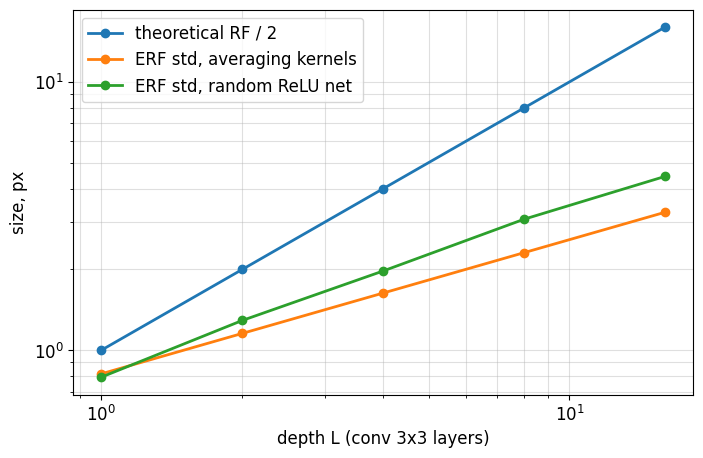

In [18]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?


**Ответ.**

**1. Усредняющая сеть**

Теоретическое receptive field (RF) растёт линейно с глубиной сети:

$$
r_L/2 = L.
$$

Эффективное receptive field (ERF) увеличивается медленнее:

$$
\operatorname{std}(ERF) = \sqrt{\frac{2L}{3}}.
$$

При увеличении глубины от $L=1$ до $L=16$ стандартное отклонение ERF возрастает с **0.82 до 3.27**. Наклон на log-log графике равен примерно 0.5, что соответствует зависимости от $\sqrt{L}$.

При этом отношение ERF к теоретическому RF уменьшается:

$$
\frac{\operatorname{std}(ERF)}{r_L/2}
= \sqrt{\frac{2}{3L}}.
$$

Таким образом, с увеличением глубины сети эффективная область составляет всё меньшую долю теоретического receptive field.

**2. Случайная ReLU-сеть**

В случайной ReLU-сети ERF также растёт медленнее теоретического RF. Его стандартное отклонение увеличивается с 0.79 до 4.44, а наклон log-log графика составляет приблизительно 0.62.

По сравнению с усредняющей сетью ERF растёт немного быстрее и при $L=16$ оказывается шире: 4.44 против 3.27.

Это объясняется случайной инициализацией весов и нелинейностью ReLU, из-за которых вклад различных путей распространения сигнала становится неравномерным.

**Вывод.**

Эксперимент подтверждает, что эффективное receptive field занимает лишь часть теоретического и его относительный размер уменьшается с глубиной сети. Основной вклад в выход сосредоточен в центральной области, что согласуется с результатами Luo et al. (2016).

При этом исследование ограничено случайной инициализацией, одной реализацией весов и глубиной до 16 слоёв. Обучение сети может изменить распределение ERF.


---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [19]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.num_features = num_features
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        shape = (1, -1, 1, 1)
        if self.training:
            n = x.numel() // x.shape[1]
            if n < 2:
                raise ValueError(f'Expected more than 1 value per channel when training, got input size {tuple(x.shape)}')
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), correction=0)
            with torch.no_grad():
                self.num_batches_tracked.add_(1)
                m = self.momentum if self.momentum is not None else 1.0 / self.num_batches_tracked.item()
                self.running_mean.mul_(1 - m).add_(m * mean.detach())
                self.running_var.mul_(1 - m).add_(m * var.detach() * n / (n - 1))
        else:
            mean, var = self.running_mean, self.running_var
        x_hat = (x - mean.reshape(shape)) / torch.sqrt(var.reshape(shape) + self.eps)
        return x_hat * self.weight.reshape(shape) + self.bias.reshape(shape)

In [20]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?


**Ответ.**

В Batch Normalization используются две оценки дисперсии:

- **Смещённая дисперсия** - при нормировке текущего батча, чтобы нормализованные значения имели единичную дисперсию.
- **Несмещённая дисперсия** - для обновления `running_var`, поскольку она учитывает поправку на смещение выборочной дисперсии и используется при инференсе.

Смещённая оценка систематически занижает дисперсию. Поэтому для `running_var` применяется поправка:

$$
s^2_{\mathrm{unbiased}} =
\frac{n}{n-1}s^2_{\mathrm{biased}},
\qquad n = BHW.
$$

**1. Батч $B=4$, карта $5\times5$**

Количество значений на канал:

$$
n = 4\cdot5\cdot5 = 100.
$$

Коэффициент поправки:

$$
\frac{n}{n-1} = \frac{100}{99}
\approx 1.0101.
$$

Таким образом, несмещённая оценка дисперсии больше смещённой примерно на 1,01%.

**2. Батч $B=2$, карта $1\times1$**

Количество значений на канал:

$$
n = 2\cdot1\cdot1 = 2.
$$

Коэффициент поправки:

$$
\frac{n}{n-1} = \frac{2}{1} = 2.
$$

В этом случае несмещённая оценка в **2 раза больше** смещённой.

**Вывод.**

При большом количестве элементов разница между оценками незначительна. При малых батчах и небольших пространственных размерах она становится существенной: статистики оказываются менее устойчивыми, что может приводить к заметным различиям между поведением BatchNorm при обучении и инференсе.


## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** В `eval()` для каждого выходного канала $o$:
$$
\mathrm{BN}(z)_o = \gamma_o\,\frac{z_o - \hat\mu_o}{\sqrt{\hat\sigma_o^2 + \epsilon}} + \beta_o, \qquad z_o = (W * x)_o + b_o .
$$
Обозначим $a_o = \dfrac{\gamma_o}{\sqrt{\hat\sigma_o^2 + \epsilon}}$. Свёртка линейна по весам, поэтому $a_o (W * x)_o = (a_o W_o) * x$, и
$$
W'_{o,\cdot,\cdot,\cdot} = a_o\, W_{o,\cdot,\cdot,\cdot}, \qquad b'_o = a_o\,(b_o - \hat\mu_o) + \beta_o ,
$$
где $b_o = 0$, если у свёртки нет bias. Масштаб применяется к целой «строке» весов выходного канала, поэтому формула не зависит от stride, padding, dilation и groups (при groups каждая группа выходов умножается на свои $a_o$). Для `padding_mode='reflect'` тоже верно: паддинг применяется ко входу, а не к весам.

In [21]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    w = conv.weight
    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size, stride=conv.stride,
                      padding=conv.padding, dilation=conv.dilation, groups=conv.groups, bias=True,
                      padding_mode=conv.padding_mode, device=w.device, dtype=w.dtype)
    var = bn.running_var.to(w.dtype)
    mean = bn.running_mean.to(w.dtype)
    gamma = bn.weight.to(w.dtype) if bn.weight is not None else torch.ones_like(var)
    beta = bn.bias.to(w.dtype) if bn.bias is not None else torch.zeros_like(var)
    scale = gamma / torch.sqrt(var + bn.eps)
    b = conv.bias if conv.bias is not None else torch.zeros_like(mean)
    fused.weight.copy_(w * scale.reshape(-1, 1, 1, 1))
    fused.bias.copy_((b - mean) * scale + beta)
    fused.train(conv.training)
    return fused


def fuse_sequential(seq):
    modules = list(seq.children())
    fused, i = [], 0
    while i < len(modules):
        m = modules[i]
        nxt = modules[i + 1] if i + 1 < len(modules) else None
        if (isinstance(m, nn.Conv2d) and isinstance(nxt, nn.BatchNorm2d)
                and nxt.num_features == m.out_channels and nxt.running_mean is not None):
            fused.append(fuse_conv_bn(m, nxt))
            i += 2
        else:
            fused.append(copy.deepcopy(m))
            i += 1
    return nn.Sequential(*fused).train(seq.training)

In [22]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [23]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [24]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 152.7 ms   fused: 140.9 ms   speedup 1.08x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В `train()` BatchNorm использует среднее и дисперсию текущего батча и обновляет буферы; такое преобразование зависит от входных примеров и не является фиксированной аффинной функцией. В `eval()` статистики фиксированы, поэтому BN можно алгебраически включить в веса и bias свёртки без изменения предсказаний (с точностью до округления).

Слияние уменьшает число обращений к памяти и запусков kernels, но степень ускорения зависит от устройства, размеров свёртки и бэкенда. Время без слияния и после него измеряется открытым бенчмарком в ячейке выше и автоматически приводится ниже.


In [25]:
show_result('2.2 — Conv–BN fusion',
    f'- Conv + BN: **{t_bn * 1000:.2f} мс**; fused: **{t_fused * 1000:.2f} мс**; '
    f'измеренное ускорение **{t_bn / max(t_fused, 1e-12):.2f}×**. '
    'Замер зависит от устройства, нагрузки CPU/GPU, настроек PyTorch и числа повторений.')


### Фактический результат — 2.2 — Conv–BN fusion

- Conv + BN: **152.69 мс**; fused: **140.94 мс**; измеренное ускорение **1.08×**. Замер зависит от устройства, нагрузки CPU/GPU, настроек PyTorch и числа повторений.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Требуем $\mathrm{Var}(h_i) = \mathrm{Var}(h^{\text{prev}})$, т.е. $n\,v\,\mathbb E z_j^2 = \mathrm{Var}(h^{\text{prev}})$.

- **ReLU:** если $h^{\text{prev}}$ симметрично относительно 0, то $\mathbb E[\mathrm{ReLU}(h)^2] = \tfrac12 \mathbb E h^2 = \tfrac12 \mathrm{Var}(h^{\text{prev}})$. Отсюда $n v / 2 = 1$, т.е. $v = 2/n$ (Kaiming / He).
- **tanh в линейном режиме:** $\tanh(h) \approx h$, $\mathbb E z^2 \approx \mathrm{Var}(h^{\text{prev}})$, значит $v = 1/n$ (LeCun; Xavier с $v = 2/(n_{\text{in}} + n_{\text{out}})$ при квадратных слоях даёт то же).
- **PyTorch default** $\mathcal U(-1/\sqrt n, 1/\sqrt n)$: $v = \frac{(2/\sqrt n)^2}{12} = \frac{1}{3n}$. Для ReLU $\mathrm{Var}(h) = n \cdot \frac{1}{3n} \cdot \frac12 \mathrm{Var}(h^{\text{prev}}) = \frac16 \mathrm{Var}(h^{\text{prev}})$, т.е. стандартное отклонение за слой умножается на $1/\sqrt6 \approx 0.408$ — за 50 слоёв это $\approx 10^{-19.5}$. Измеренный средний множитель: 0.409 (тест в ячейке ниже), что совпадает с $1/\sqrt6 = 0.408$.

In [26]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    with torch.no_grad():
        for _ in range(depth):
            weight = torch.empty(width, width)
            init(weight)
            h = act(h @ weight.T)
            stds.append(h.std().item())
    return stds

In [27]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

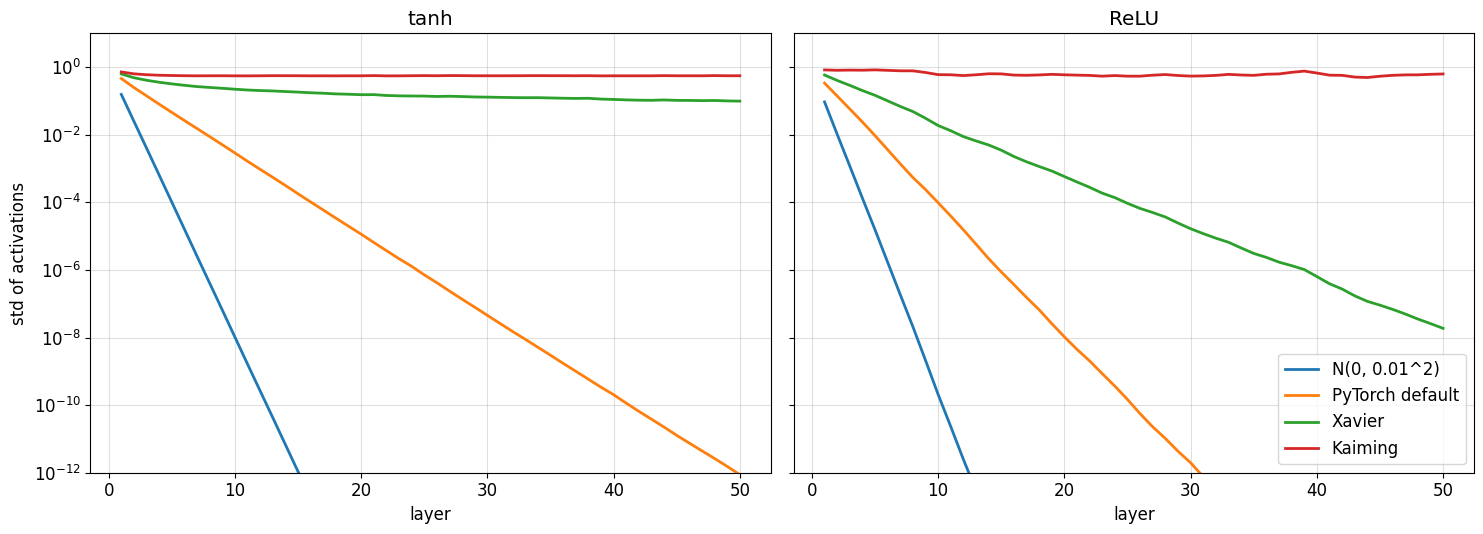

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Значения стандартного отклонения на слоях 1, 10 и 50 рассчитываются следующей ячейкой из `stds`. Для ReLU теория предсказывает близкое сохранение масштаба при инициализации Kaiming (`Var(W)=2/fan_in`), в то время как Xavier (`1/fan_in`) даёт тенденцию к затуханию. Для `tanh` насыщение дополнительно уменьшает амплитуду и производные; Kaiming может стабилизировать прямой сигнал ценой насыщения. Слишком маленькие веса и инициализация по умолчанию в этой длинной сети без нормализации обычно ведут к затуханию.

Этот эксперимент моделирует 50 полносвязных слоёв без BatchNorm и residual-связей. Для ResNet с нормализацией статистика будет иной: identity-связи и BN помогают передавать сигнал, а адаптивная оптимизация уменьшает чувствительность к разным масштабам обновлений.


In [29]:
lines = ['| Инициализация | Активация | Std, слой 1 | Слой 10 | Слой 50 | Отношение 50/1 |',
         '|---|---|---:|---:|---:|---:|']
for (init_name, act_name), values in stds.items():
    lines.append(f'| {init_name} | {act_name} | {values[0]:.4g} | {values[9]:.4g} | {values[49]:.4g} | {values[49] / max(values[0], 1e-35):.4g} |')
show_result('3.1 — масштаб активаций', '\n'.join(lines) + '\n\n' +
            'Числа получены на текущем seed; небольшие отличия допустимы при смене окружения.')


### Фактический результат — 3.1 — масштаб активаций

| Инициализация | Активация | Std, слой 1 | Слой 10 | Слой 50 | Отношение 50/1 |
|---|---|---:|---:|---:|---:|
| N(0, 0.01^2) | tanh | 0.1563 | 1.033e-08 | 1.494e-40 | 9.562e-40 |
| N(0, 0.01^2) | ReLU | 0.09359 | 2.058e-10 | 0 | 0 |
| PyTorch default | tanh | 0.4606 | 0.00289 | 8.735e-13 | 1.897e-12 |
| PyTorch default | ReLU | 0.3375 | 9.736e-05 | 3.221e-20 | 9.545e-20 |
| Xavier | tanh | 0.6278 | 0.2222 | 0.09872 | 0.1572 |
| Xavier | ReLU | 0.585 | 0.01872 | 1.87e-08 | 3.196e-08 |
| Kaiming | tanh | 0.721 | 0.5524 | 0.5565 | 0.7718 |
| Kaiming | ReLU | 0.8273 | 0.5991 | 0.6274 | 0.7584 |

Числа получены на текущем seed; небольшие отличия допустимы при смене окружения.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [30]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                lr, eps, wd = group['lr'], group['eps'], group['weight_decay']
                grad = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                    state['exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                state['step'] += 1
                t = state['step']
                m, v = state['exp_avg'], state['exp_avg_sq']

                p.mul_(1 - lr * wd)
                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                if group['bias_correction']:
                    bc1, bc2 = 1 - beta1 ** t, 1 - beta2 ** t
                else:
                    bc1 = bc2 = 1.0
                denom = (v / bc2).sqrt_().add_(eps)
                p.addcdiv_(m, denom, value=-lr / bc1)

In [31]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [32]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


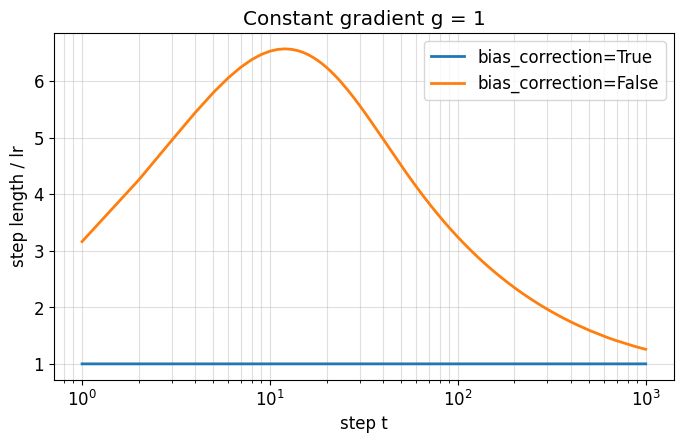

In [33]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?


**Ответ.**

### 1. Вывод длины шага без bias correction

Пусть градиент постоянен: $g_t = 1$, а начальные моменты равны $m_0 = v_0 = 0$.

Тогда экспоненциальные скользящие средние имеют вид:

$$
m_t = 1 - \beta_1^t,
\qquad
v_t = 1 - \beta_2^t.
$$

Без коррекции смещения относительная длина шага Adam определяется формулой:

$$
\frac{|\Delta \theta_t|}{\eta}
=
\frac{1-\beta_1^t}
{\sqrt{1-\beta_2^t}+\varepsilon}.
$$

### 2. Численные результаты

Для стандартных параметров $\beta_1 = 0.9$ и $\beta_2 = 0.999$ при пренебрежимо малом $\varepsilon$ получаем:

| Шаг $t$ | Длина шага относительно $\eta$ |
|:---:|:---:|
| 1 | 3.16 |
| 10 | 6.53 |
| 12 | 6.57 (максимум) |
| 100 | 3.24 |
| 1000 | 1.26 |

Максимальная длина шага достигается приблизительно на **12-м шаге** и составляет $6.57\eta$, что согласуется с результатом вычислений.

### 3. Почему возникает такой эффект?

Первый момент $m_t$ накапливается относительно быстро, поскольку $\beta_1 = 0.9$. Второй момент $v_t$ накапливается значительно медленнее из-за $\beta_2 = 0.999$.

В результате знаменатель в формуле обновления первоначально оказывается слишком маленьким, что приводит к увеличению шага оптимизатора.

При использовании bias correction оба момента корректируются:

$$
\hat m_t = \frac{m_t}{1-\beta_1^t},
\qquad
\hat v_t = \frac{v_t}{1-\beta_2^t}.
$$

Для постоянного градиента $g_t=1$ длина скорректированного шага приблизительно равна $\eta$ с самого начала обучения.

### 4. Чем это опасно?

В первые сотни итераций шаг без коррекции может в несколько раз превышать заданный learning rate. Это особенно опасно в начале обучения, когда веса ещё случайны, а градиенты могут быть нестабильными.

Возможные последствия:

- резкие скачки функции потерь;
- нестабильное обучение и расходимость;
- слишком большие обновления параметров.

**Вывод.** Bias correction устраняет начальное смещение оценок моментов и позволяет избежать чрезмерно больших шагов оптимизатора. Дополнительно для стабилизации обучения может использоваться learning rate warmup.


## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [34]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, max(0.0, step / total_steps)) if total_steps > 0 else 1.0
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [35]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

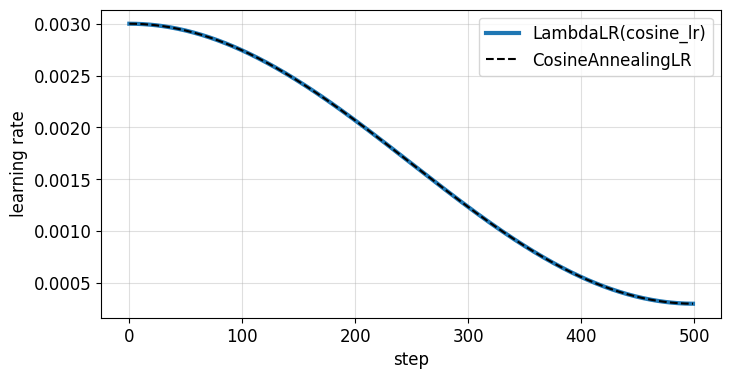

In [36]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность Adam нормирует шаг по масштабу градиента ($\hat m/\sqrt{\hat v}$), но **не** уменьшает его около минимума: при стохастических градиентах $\hat m_t$ не стремится к нулю (в нём шум батча), а $\sqrt{\hat v_t}$ отражает дисперсию шума, поэтому отношение остаётся порядка единицы, и шаг остаётся $\sim\eta$ на параметр.

SGD/Adam с постоянным шагом около минимума не сходится к точке: итерации блуждают в окрестности минимума (стационарное распределение), размер которой пропорционален $\eta \cdot$ (дисперсия шума градиента). Ожидаемый loss «застревает» на уровне $L^* + O(\eta\sigma^2)$. Уменьшение $\eta$ к концу (cosine) уменьшает этот шумовой «шар» и усредняет итерации, поэтому в последние эпохи train loss резко падает, а test accuracy растёт. Начало с большого $\eta$ при этом даёт быстрый прогресс и неявную регуляризацию.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [37]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [10:01<00:00, 283kB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

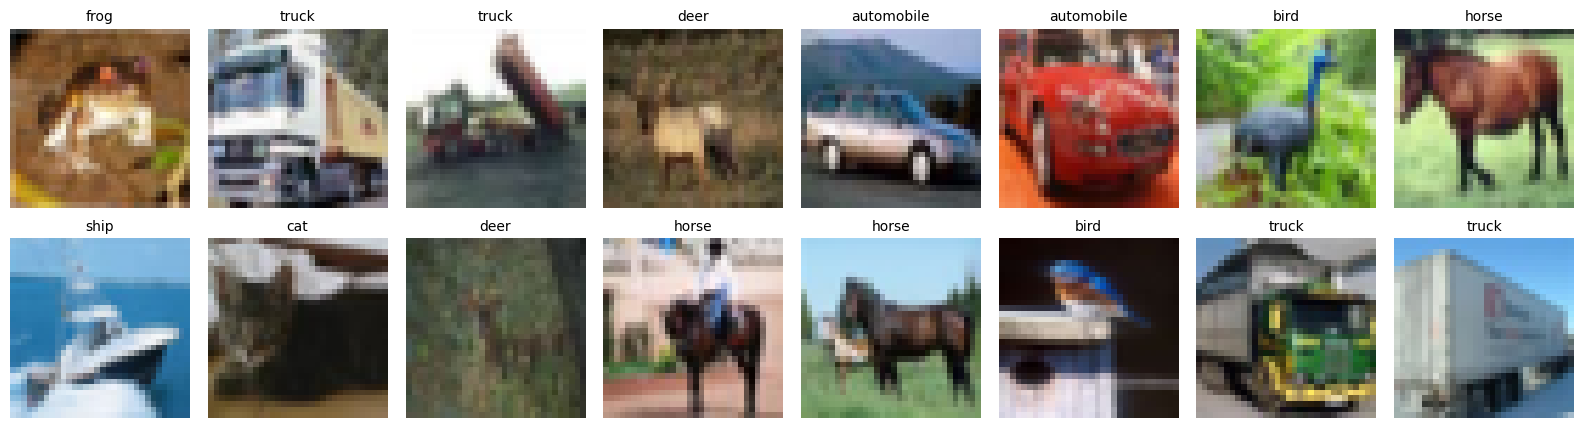

In [38]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [39]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )
    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                                              nn.BatchNorm2d(c_out))
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        stages, c = [], widths[0]
        for i, width in enumerate(widths):
            blocks = []
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                blocks.append(Block(c, width, stride, residual, separable))
                c = width
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(self.pool(x).flatten(1))

In [40]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [41]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    if device.type == 'cuda':
        torch.backends.cudnn.benchmark = True
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    groups = [g for g in [dict(params=decay, weight_decay=weight_decay),
                          dict(params=no_decay, weight_decay=0.0)] if g['params']]
    optimizer = MyAdamW(groups, lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps, 0.0))
    for epoch in range(epochs):
        model.train()
        loss_sum = torch.zeros((), device=device)
        n_seen = 0
        for x, y in iterate_batches(X_train, Y_train, batch_size, shuffle=True, transform=normalize):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * len(y)
            n_seen += len(y)
        history['train_loss'].append((loss_sum / n_seen).item())
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))
        if log:
            print(f'epoch {epoch + 1:>3}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  lr {scheduler.get_last_lr()[0]:.2e}  '
                  f'{time.time() - start:.0f} s')
    model.eval()
    return history

In [42]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch   1/20  train loss 1.4392  test acc 0.5001  lr 2.98e-03  12 s
epoch   2/20  train loss 0.9646  test acc 0.5929  lr 2.93e-03  22 s
epoch   3/20  train loss 0.7594  test acc 0.6933  lr 2.84e-03  32 s
epoch   4/20  train loss 0.6405  test acc 0.7246  lr 2.71e-03  42 s
epoch   5/20  train loss 0.5572  test acc 0.7704  lr 2.56e-03  51 s
epoch   6/20  train loss 0.4880  test acc 0.7600  lr 2.38e-03  61 s
epoch   7/20  train loss 0.4196  test acc 0.7450  lr 2.18e-03  71 s
epoch   8/20  train loss 0.3621  test acc 0.7911  lr 1.96e-03  81 s
epoch   9/20  train loss 0.3079  test acc 0.7611  lr 1.73e-03  92 s
epoch  10/20  train loss 0.2534  test acc 0.8128  lr 1.50e-03  102 s
epoch  11/20  train loss 0.2013  test acc 0.7996  lr 1.27e-03  112 s
epoch  12/20  train loss 0.1476  test acc 0.7893  lr 1.04e-03  122 s
epoch  13/20  train loss 0.0999  test acc 0.8069  lr 8.19e-04  133 s
epoch  14/20  train loss 0.0599  test acc 0.8216  lr 6.18e-04  143 s
epoch  15/20  train loss 0.0360  test acc 0

{'train acc': 0.9998999834060669, 'test acc': 0.8294999599456787}

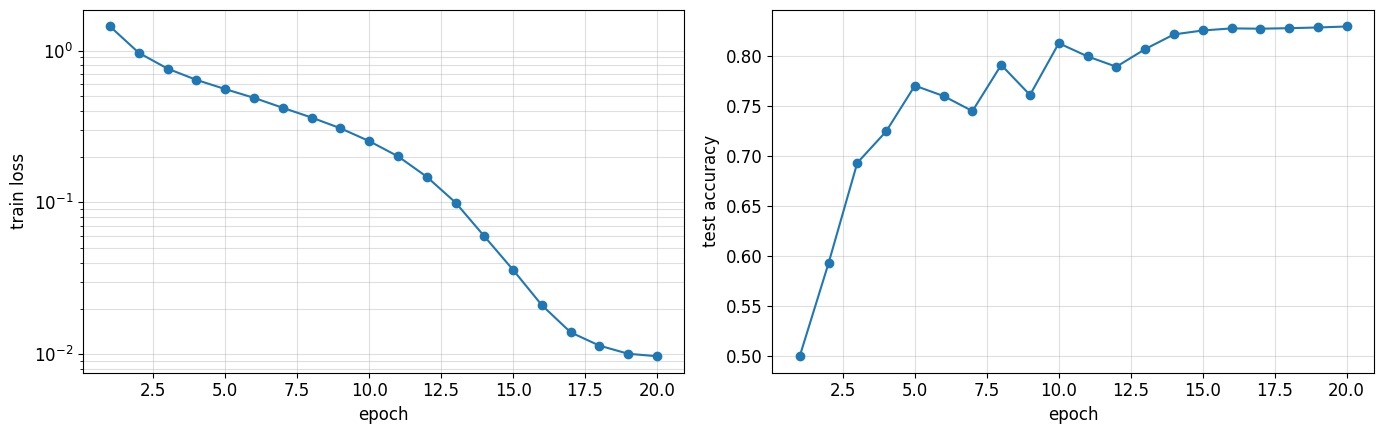

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
plt.gcf().savefig(Path('artifacts/plots') / 'cifar_resnet20.png', dpi=140, bbox_inches='tight')
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** Train accuracy измеряется на первых 10 000 объектах обучающей выборки, test accuracy - на отложенной выборке. Разница между ними позволяет оценить обобщающую способность, но сама по себе не доказывает причину ухудшения (в эксперименте нет аугментаций, используется один seed). Ниже автоматически указаны финальные accuracy, разрыв, loss и последние эпохи. Cosine schedule уменьшает шаг оптимизации к концу обучения; направление и величину фактических изменений проверяем по `history_cifar`, не предполагая заранее ни плато, ни достижения ориентира 0.82.


In [44]:
gap_pp = 100 * (train_acc - test_acc)
last = min(4, len(history_cifar['train_loss']))
loss_tail = history_cifar['train_loss'][-last:]
acc_tail = history_cifar['test_acc'][-last:]
trend = 'уменьшился' if loss_tail[-1] < loss_tail[0] else ('увеличился' if loss_tail[-1] > loss_tail[0] else 'не изменился')
show_result('4.2 — ResNet-20',
    f'- Train accuracy (первые 10 000): **{train_acc:.2%}**, test accuracy: **{test_acc:.2%}**; разрыв train−test: **{gap_pp:+.2f} п.п.**\n'
    f'- Последний train loss: **{history_cifar["train_loss"][-1]:.4f}**; за последние {last} эпох(и) loss {trend}.\n'
    f'- Последние значения train loss: `{[round(v, 4) for v in loss_tail]}`; test accuracy: `{[round(v, 4) for v in acc_tail]}`.\n'
    f'- Ориентир test accuracy {TARGET_ACC:.0%}: **{"достигнут" if test_acc >= TARGET_ACC else "не достигнут"}**. '
    'Это результат одного запуска; он не является гарантией качества на других seed.')


### Фактический результат — 4.2 — ResNet-20

- Train accuracy (первые 10 000): **99.99%**, test accuracy: **82.95%**; разрыв train−test: **+17.04 п.п.**
- Последний train loss: **0.0097**; за последние 4 эпох(и) loss уменьшился.
- Последние значения train loss: `[0.014, 0.0114, 0.0101, 0.0097]`; test accuracy: `[0.8273, 0.8278, 0.8285, 0.8295]`.
- Ориентир test accuracy 82%: **достигнут**. Это результат одного запуска; он не является гарантией качества на других seed.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [45]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [46]:
ablation = {}
for name, cfg in ABLATIONS.items():
    print(name)
    set_seed(0)
    model = ResNetCIFAR(**cfg)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    seconds = time.perf_counter() - started
    RUN_TIMES[f'cifar_{name}_seconds'] = seconds
    ablation[name] = dict(
        params=n_params(model),
        train_acc=accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000]),
        test_acc=hist['test_acc'][-1],
        minutes=seconds / 60,
        history=hist,
    )

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

plain-20
epoch   1/10  train loss 1.7039  test acc 0.3290  lr 2.93e-03  10 s
epoch   2/10  train loss 1.3426  test acc 0.4945  lr 2.71e-03  20 s
epoch   3/10  train loss 1.0916  test acc 0.6132  lr 2.38e-03  30 s
epoch   4/10  train loss 0.9329  test acc 0.6612  lr 1.96e-03  40 s
epoch   5/10  train loss 0.8187  test acc 0.6720  lr 1.50e-03  50 s
epoch   6/10  train loss 0.7173  test acc 0.7164  lr 1.04e-03  59 s
epoch   7/10  train loss 0.6287  test acc 0.7347  lr 6.18e-04  69 s
epoch   8/10  train loss 0.5576  test acc 0.7647  lr 2.86e-04  79 s
epoch   9/10  train loss 0.5044  test acc 0.7773  lr 7.34e-05  89 s
epoch  10/10  train loss 0.4754  test acc 0.7783  lr 0.00e+00  99 s
plain-56
epoch   1/10  train loss 1.9696  test acc 0.2610  lr 2.93e-03  30 s
epoch   2/10  train loss 1.8149  test acc 0.2517  lr 2.71e-03  59 s
epoch   3/10  train loss 1.7304  test acc 0.3282  lr 2.38e-03  88 s
epoch   4/10  train loss 1.6437  test acc 0.3453  lr 1.96e-03  118 s
epoch   5/10  train loss 1.57

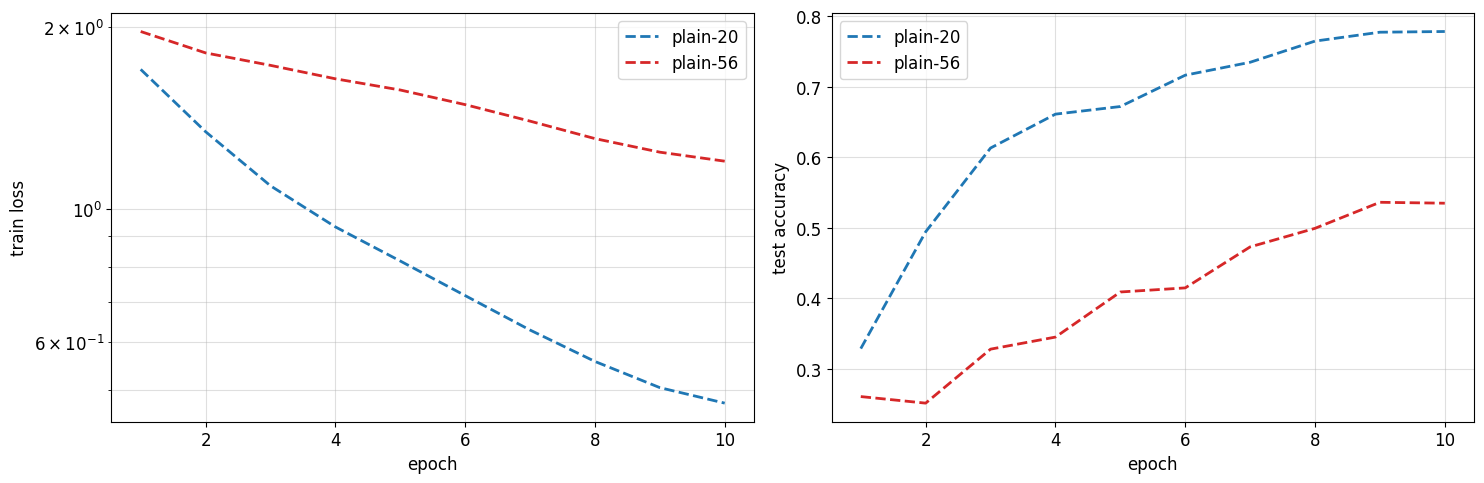

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
plt.gcf().savefig(Path('artifacts/plots') / 'cifar_plain_ablation.png', dpi=140, bbox_inches='tight')
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Сопоставляем plain-20 и plain-56 при одинаковых seed, числе эпох, LR и данных. Критерий *degradation*: если более глубокая сеть хуже на обучающей выборке (выше train loss и/или ниже train accuracy), это согласуется с трудностью оптимизации; если хуже лишь на test при лучшем train, это согласуется с переобучением. Итоговые измерения и вывод по знакам разностей приведены ниже. Эксперимент использует один seed и ограниченное число эпох, поэтому нельзя делать вывод о предельной обучаемости архитектур.

**Контрольный эксперимент:** при необходимости обучить ResNet-56 (`residual=True`) с тем же бюджетом. Это помогло бы изолировать эффект shortcut-связей от чисто количественного увеличения глубины.


In [48]:
a20, a56 = ablation['plain-20'], ablation['plain-56']
l20, l56 = a20['history']['train_loss'][-1], a56['history']['train_loss'][-1]
if l56 > l20 and a56['train_acc'] < a20['train_acc']:
    interp = 'Глубокая plain-56 хуже по train loss и train accuracy: наблюдение согласуется с degradation/трудностями оптимизации.'
elif l56 < l20 and a56['train_acc'] >= a20['train_acc'] and a56['test_acc'] < a20['test_acc']:
    interp = 'Более глубокая сеть лучше на train, но хуже на test: наблюдение согласуется с переобучением.'
else:
    interp = 'Train loss и accuracy не дают однозначной картины degradation; необходим дополнительный контроль и повторение с другим seed.'
lines = ['| Модель | Параметров | Train loss | Train accuracy | Test accuracy | Время, мин |',
         '|---|---:|---:|---:|---:|---:|']
for key, item in [('plain-20', a20), ('plain-56', a56)]:
    lines.append(f'| {key} | {item["params"]:,} | {item["history"]["train_loss"][-1]:.4f} | {item["train_acc"]:.2%} | {item["test_acc"]:.2%} | {item["minutes"]:.2f} |')
lines.append(f'\nВремя plain-56 / plain-20: **{a56["minutes"] / max(a20["minutes"], 1e-9):.2f}×**. {interp}')
show_result('4.3 — абляции', '\n'.join(lines))


### Фактический результат — 4.3 — абляции

| Модель | Параметров | Train loss | Train accuracy | Test accuracy | Время, мин |
|---|---:|---:|---:|---:|---:|
| plain-20 | 269,722 | 0.4754 | 84.52% | 77.83% | 1.65 |
| plain-56 | 853,018 | 1.1994 | 56.44% | 53.50% | 4.91 |

Время plain-56 / plain-20: **2.97×**. Глубокая plain-56 хуже по train loss и train accuracy: наблюдение согласуется с degradation/трудностями оптимизации.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [49]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.3MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [50]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [51]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [52]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.917, 'FGSM, eps=0.1': 0.073, 'PGD-20, eps=0.1': 0.005}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [53]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    view = (-1,) + (1,) * (x.ndim - 1)
    x_adv = x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        g_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(view)
        x_adv = x_adv.detach() + alpha * grad / g_norm
        delta = x_adv - x
        d_norm = delta.flatten(1).norm(dim=1).view(view)
        factor = torch.clamp(eps / d_norm.clamp_min(1e-12), max=1.0)
        x_adv = (x + delta * factor).clamp(0, 1)
    return x_adv.detach()

In [54]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.922; маленькое падение требует диагностики.


(0.922, 0.0)

In [55]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.917,
  0.5: 0.443,
  1.0: 0.078,
  1.5: 0.011,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.007)

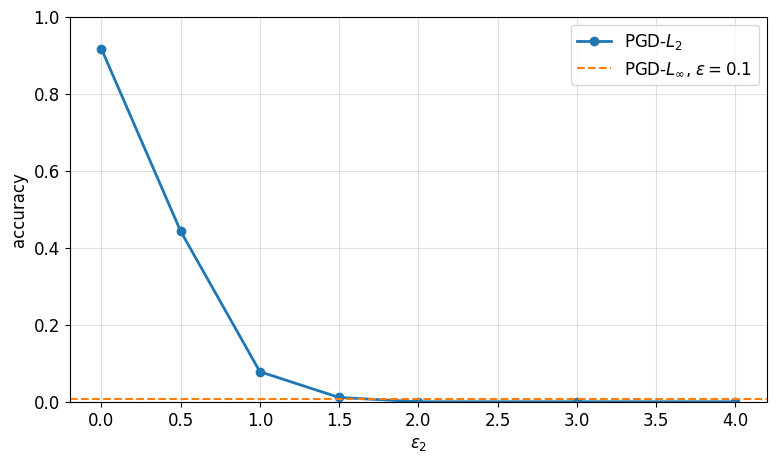

In [56]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
plt.gcf().savefig(Path('artifacts/plots') / 'fashion_pgd_l2_curve.png', dpi=140, bbox_inches='tight')
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.004


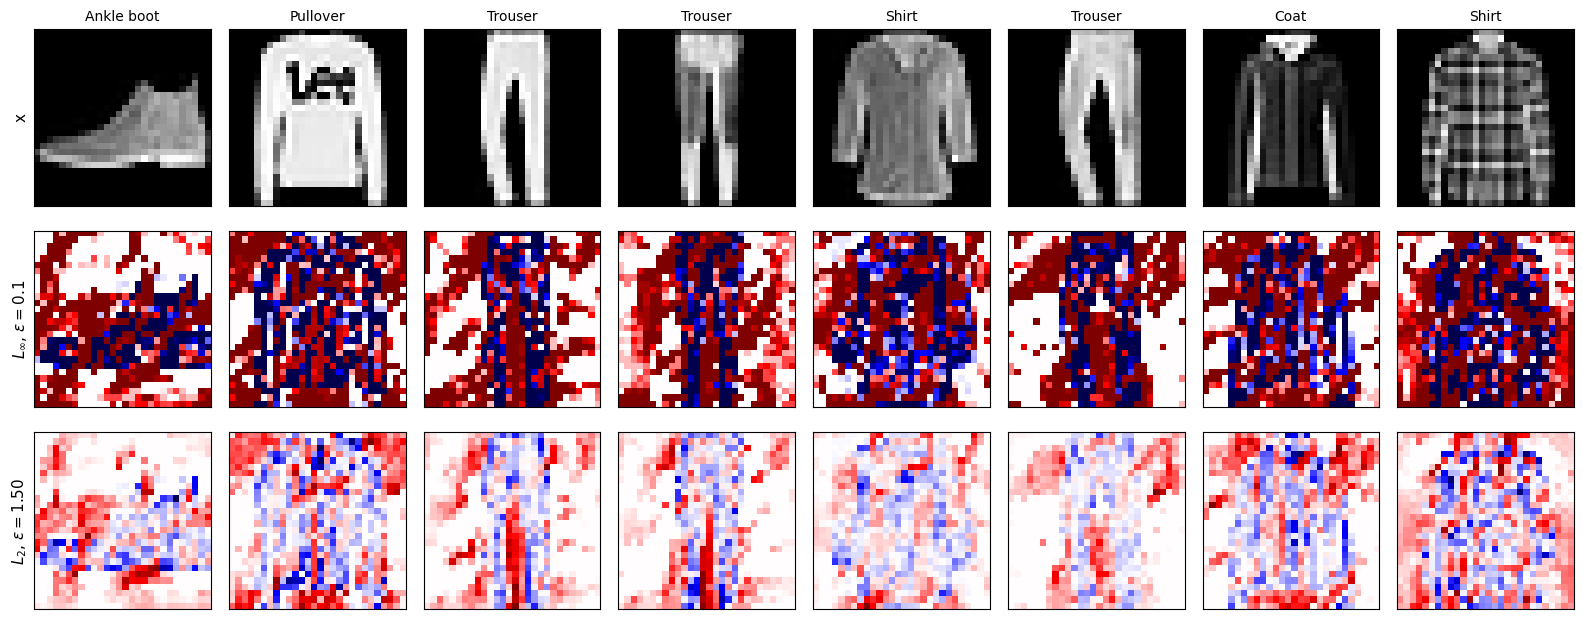

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.104
$L_2$, $\varepsilon=1.50$    L_inf = 0.261   L_2 = 1.492


In [57]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
plt.gcf().savefig(Path('artifacts/plots') / 'fashion_perturbations.png', dpi=140, bbox_inches='tight')
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Нельзя приравнивать радиусы разных норм: сравниваем измеренную accuracy на сетке `eps_l2` с PGD-$L_\infty$ при $\varepsilon_\infty=0.1$. Ближайшую точку и разницу accuracy вычисляем ниже; если разница велика, выбранная сетка недостаточно точна для сравнения атак одинаковой силы.

У sign-шагов $L_\infty$-PGD возмущение часто распределяется по многим пикселям, и его $L_2$-норма может доходить до $0.1\sqrt{784}=2.8$ (верхняя граница для 28×28). Нормированный градиент $L_2$-PGD распределяет бюджет пропорционально $|g_i|$, поэтому сильнее изменяются области с большими производными. Реальную локализацию сравниваем по графику; `clamp(0,1)` меняет картину особенно на чёрном фоне.


In [58]:
a2 = float(acc_l2[match_idx]); gap = abs(a2 - acc_linf)
linf_delta, l2_delta = list(deltas.values())
mean_norm2_linf = linf_delta.flatten(1).norm(dim=1).mean().item()
mean_inf_l2 = l2_delta.abs().flatten(1).max(dim=1).values.mean().item()
show_result('5.1 — PGD-L2',
  f'- Ближайшая точка сетки: **eps2={eps2_match:g}**, PGD-L2 accuracy **{a2:.2%}**, '
  f'PGD-Linf(eps=0.1) accuracy **{acc_linf:.2%}**, разница **{gap:.2%}**.\n'
  f'- На 8 иллюстрируемых примерах средняя L2-норма возмущения PGD-Linf: **{mean_norm2_linf:.3f}**; '
  f'средняя Linf-норма возмущения PGD-L2: **{mean_inf_l2:.3f}**.\n'
  + ('- **Ограничение:** расхождение accuracy больше 5 п.п.; эта сетка даёт только приближённое сопоставление силы атак.' if gap > 0.05
     else '- На заданной сетке различие в accuracy не превышает 5 п.п.; геометрия возмущений при этом различается.'))


### Фактический результат — 5.1 — PGD-L2

- Ближайшая точка сетки: **eps2=1.5**, PGD-L2 accuracy **1.10%**, PGD-Linf(eps=0.1) accuracy **0.70%**, разница **0.40%**.
- На 8 иллюстрируемых примерах средняя L2-норма возмущения PGD-Linf: **2.104**; средняя Linf-норма возмущения PGD-L2: **0.261**.
- На заданной сетке различие в accuracy не превышает 5 п.п.; геометрия возмущений при этом различается.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [59]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        alpha = 2.5 * eps / steps
        counts = torch.bincount(y.cpu(), minlength=n_classes)[:n_classes].double()
        hits = torch.zeros(n_classes, n_classes, dtype=torch.float64)
        for t in range(n_classes):
            for i in range(0, len(x), 128):
                xb, yb = x[i:i + 128], y[i:i + 128]
                keep = yb != t
                if not keep.any():
                    continue
                xb, yb = xb[keep], yb[keep]
                x_adv = pgd_targeted(model, xb, torch.full_like(yb, t), eps, alpha, steps)
                with torch.no_grad():
                    hit = model(x_adv).argmax(dim=1) == t
                hits[:, t] += torch.bincount(yb[hit].cpu(), minlength=n_classes)[:n_classes].double()
        S = (hits / counts[:, None]).float()
        S[counts == 0] = float('nan')
        S.fill_diagonal_(float('nan'))
        return S

In [60]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.765; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.89 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.07 0.   0.74 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


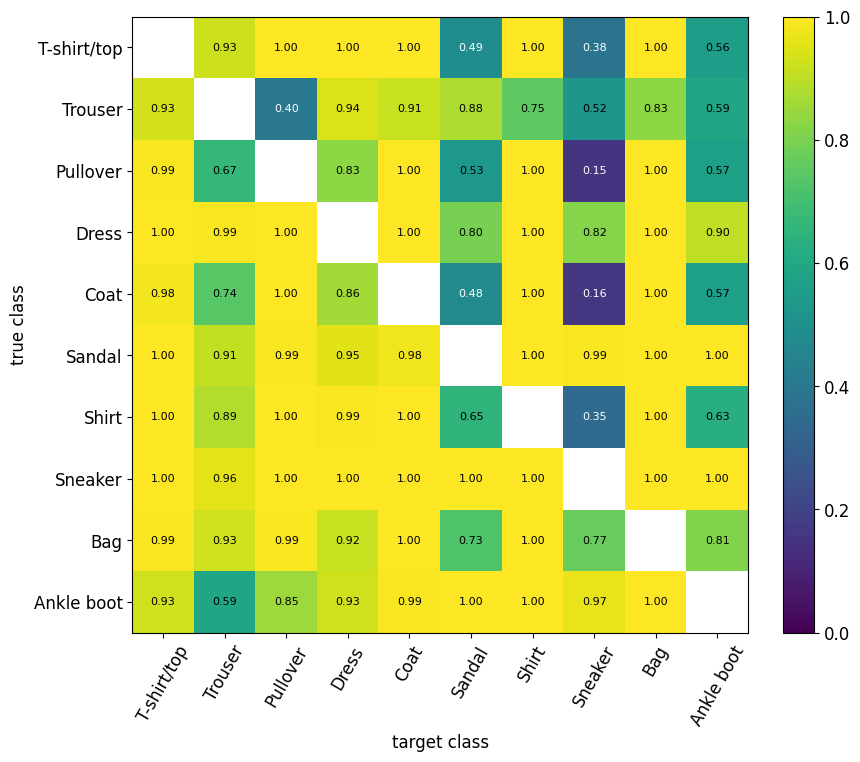

In [61]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
    plt.gcf().savefig(Path('artifacts/plots') / 'fashion_targeted_matrix.png', dpi=140, bbox_inches='tight')
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Для выбранной targeted-ветки матрица $S[s,t]$ показывает долю исходных объектов класса $s$, которые атака заставила предсказать как класс $t$. На диагонали значение не определено. Автоматический отчёт ниже называет три наиболее и наименее успешные направленные пары, показывает максимальную асимметрию $S[s,t]-S[t,s]$ и clean confusion для той же пары.

Асимметрия ожидаема: области решения классов могут различаться по форме и размеру, а исходные изображения находятся на разном расстоянии от границ. Путаница без атаки может коррелировать с успешностью targeted-атаки, но не обязана её предсказывать. Размер выборки и один запуск PGD ограничивают точность оценок.


In [62]:
if ATTACK_TRACK == 'targeted':
    triples = [(float(S[s, t]), s, t) for s in range(10) for t in range(10) if s != t and torch.isfinite(S[s, t])]
    triples.sort()
    def fmt_pair(z):
        value, s, t = z
        return f'{FM_CLASSES[s]} → {FM_CLASSES[t]}: {value:.2%}'
    strongest = [f'{s}' for s in map(fmt_pair, triples[-3:][::-1])]
    weakest = [f'{s}' for s in map(fmt_pair, triples[:3])]
    asym = [(abs(float(S[s, t] - S[t, s])), s, t) for s in range(10) for t in range(s + 1, 10)
            if torch.isfinite(S[s, t]) and torch.isfinite(S[t, s])]
    gap, s, t = max(asym)
    show_result('5.2 — Targeted PGD',
        '**Легче всего (топ-3):** ' + '; '.join(strongest) + '.\n\n'
        '**Труднее всего (топ-3):** ' + '; '.join(weakest) + '.\n\n'
        f'**Максимальная асимметрия:** {FM_CLASSES[s]} → {FM_CLASSES[t]}: {S[s,t].item():.2%}; '
        f'обратно: {S[t,s].item():.2%}; разница **{gap:.2%}**. '
        f'Без атаки доля ошибок {FM_CLASSES[s]} → {FM_CLASSES[t]}: '
        f'{clean_confusion[s,t].item():.2%}; обратная: {clean_confusion[t,s].item():.2%}. '
        'Доли оценены на текущей тестовой подвыборке; причинность нельзя вывести только из матрицы.')


### Фактический результат — 5.2 — Targeted PGD

**Легче всего (топ-3):** Ankle boot → Bag: 100.00%; Ankle boot → Shirt: 100.00%; Ankle boot → Sandal: 100.00%.

**Труднее всего (топ-3):** Pullover → Sneaker: 15.32%; Coat → Sneaker: 15.65%; Shirt → Sneaker: 35.05%.

**Максимальная асимметрия:** Pullover → Sneaker: 15.32%; обратно: 100.00%; разница **84.68%**. Без атаки доля ошибок Pullover → Sneaker: 0.00%; обратная: 0.00%. Доли оценены на текущей тестовой подвыборке; причинность нельзя вывести только из матрицы.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [63]:
if ATTACK_TRACK == 'transfer':
    set_seed(1)
    model_b = train_fm(SmallCNN())
    set_seed(2)
    mlp = train_fm(nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 512), nn.ReLU(),
                                 nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 10)))
    victims = {'model A (source)': model_a, 'model B': model_b, 'MLP': mlp}
    for m in victims.values():
        m.eval()
        m.zero_grad(set_to_none=True)

    def source_examples(attack, **kwargs):
        return torch.cat([attack(model_a, XF_test[i:i + 500], YF_test[i:i + 500], **kwargs)
                          for i in range(0, len(XF_test), 500)])

    torch.manual_seed(0)
    adv_inputs = {'clean': XF_test,
                  'FGSM': source_examples(fgsm_attack, eps=0.1),
                  'PGD-20': source_examples(pgd, eps=0.1)}
    transfer = {attack: {name: attack_accuracy(m, X_adv, YF_test) for name, m in victims.items()}
                for attack, X_adv in adv_inputs.items()}
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** При `ATTACK_TRACK = 'targeted'` ветка 5.3 не выбирается и не даёт дополнительных баллов. Если переключить параметр на `transfer`, следующий вычисляемый отчёт покажет clean accuracy каждой модели и падение после атак, построенных на источнике `model_a`.


In [64]:
if ATTACK_TRACK == 'transfer':
    lines = ['| Жертва | Clean | FGSM | Δ FGSM, п.п. | PGD-20 | Δ PGD, п.п. |', '|---|---:|---:|---:|---:|---:|']
    for victim in transfer['clean']:
        clean, fg, pg = (transfer[k][victim] for k in ('clean', 'FGSM', 'PGD-20'))
        lines.append(f'| {victim} | {clean:.2%} | {fg:.2%} | {100*(clean-fg):+.2f} | {pg:.2%} | {100*(clean-pg):+.2f} |')
    show_result('5.3 — Переносимость', '\n'.join(lines) + '\n\n' +
                'Атаки построены только на model A; сравниваются с clean baseline **каждой** модели.')


---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [65]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [66]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X_eval, Y_eval = XF_test[:1000], YF_test[:1000]
    start = time.time()
    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps).detach()
            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        model.eval()
        history['clean'].append(attack_accuracy(model, X_eval, Y_eval))
        history['fgsm'].append(attack_accuracy(model, X_eval, Y_eval, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, X_eval, Y_eval, pgd, eps=eps))
        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  '
                  f'FGSM {history["fgsm"][-1]:.3f}  PGD-20 {history["pgd"][-1]:.3f}  {time.time() - start:.0f} s')
    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [67]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5  clean 0.808  FGSM 0.701  PGD-20 0.660  9 s
epoch 2/5  clean 0.824  FGSM 0.698  PGD-20 0.662  19 s
epoch 3/5  clean 0.820  FGSM 0.728  PGD-20 0.698  28 s
epoch 4/5  clean 0.834  FGSM 0.722  PGD-20 0.693  38 s
epoch 5/5  clean 0.844  FGSM 0.745  PGD-20 0.719  47 s


In [68]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.917   0.121   0.005   0.000   0.000   0.000
PGD-AT       0.844   0.796   0.720   0.483   0.131   0.001


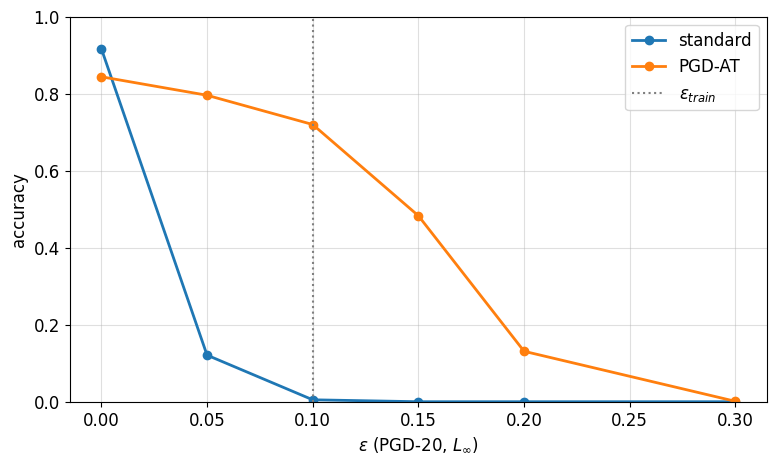

In [69]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
plt.gcf().savefig(Path('artifacts/plots') / 'fashion_pgd_at_robustness.png', dpi=140, bbox_inches='tight')
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Clean accuracy измеряем при $\varepsilon=0$, robust accuracy - под PGD-20 для каждого $\varepsilon$ из сетки. Цена устойчивости - изменение clean accuracy относительно стандартной модели; она может быть как положительной, так и отрицательной. Все разности и кривые по реальному прогону приведены ниже.

PGD-AT обучается на противоборствующих примерах внутри $L_\infty$-шара радиуса $\varepsilon_{train}=0.1$ и не даёт формальной гарантии для больших радиусов. Построение PGD-7 требует семи градиентных шагов по входу на батч, после чего следует обычный шаг обновления весов; приближённо это восемь прямых и обратных проходов против одного в обычном обучении, без учёта оценки после эпох. Реальное отношение времени определяется замерами.


In [70]:
clean_std, clean_at = robust_curves['standard'][0], robust_curves['PGD-AT'][0]
eidx = eps_grid.index(EPS_TRAIN)
rob_std, rob_at = robust_curves['standard'][eidx], robust_curves['PGD-AT'][eidx]
sec_std = RUN_TIMES.get('fashion_standard_seconds', float('nan'))
sec_at = RUN_TIMES.get('fashion_pgd_at_seconds', float('nan'))
lines = ['| eps (PGD-20) | Standard | PGD-AT |', '|---:|---:|---:|']
for e, a, b in zip(eps_grid, robust_curves['standard'], robust_curves['PGD-AT']):
    lines.append(f'| {e:g} | {a:.2%} | {b:.2%} |')
show_result('6.1 — PGD adversarial training',
    '\n'.join(lines) + '\n\n' +
    f'- Разница clean accuracy (standard − PGD-AT): **{100*(clean_std-clean_at):+.2f} п.п.**\n'
    f'- Изменение robust accuracy при eps={EPS_TRAIN}: **{100*(rob_at-rob_std):+.2f} п.п.**\n'
    f'- Время обучения standard: **{sec_std:.1f} с**; PGD-AT с оценками после эпох: **{sec_at:.1f} с** '
    f'(**{sec_at/max(sec_std, 1e-12):.1f}×**). Это время не является чистым сравнением стоимости шага по весам.')


### Фактический результат — 6.1 — PGD adversarial training

| eps (PGD-20) | Standard | PGD-AT |
|---:|---:|---:|
| 0 | 91.70% | 84.40% |
| 0.05 | 12.10% | 79.60% |
| 0.1 | 0.50% | 72.00% |
| 0.15 | 0.00% | 48.30% |
| 0.2 | 0.00% | 13.10% |
| 0.3 | 0.00% | 0.10% |

- Разница clean accuracy (standard − PGD-AT): **+7.30 п.п.**
- Изменение robust accuracy при eps=0.1: **+71.50 п.п.**
- Время обучения standard: **6.9 с**; PGD-AT с оценками после эпох: **47.1 с** (**6.9×**). Это время не является чистым сравнением стоимости шага по весам.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [71]:
def sanity_checks(model, x, y, eps):
    model.eval()
    batch = 128

    def correct_after(attack_fn):
        masks = []
        for i in range(0, len(x), batch):
            xb, yb = x[i:i + batch], y[i:i + batch]
            xa = attack_fn(xb, yb) if attack_fn is not None else xb
            with torch.no_grad():
                masks.append(model(xa).argmax(dim=1) == yb)
        return torch.cat(masks)

    clean = correct_after(None)
    fgsm_ok = clean & correct_after(lambda a, b: fgsm_attack(model, a, b, eps))
    pgd20_ok = clean & correct_after(lambda a, b: pgd(model, a, b, eps, steps=20))
    pgd100_ok = clean.clone()
    for _ in range(5):
        pgd100_ok &= correct_after(lambda a, b: pgd_attack(model, a, b, eps, alpha=2.5 * eps / 100,
                                                           steps=100, random_start=True))
    eps1_ok = clean & correct_after(lambda a, b: pgd(model, a, b, 1.0, steps=20))
    return dict(fgsm=fgsm_ok.float().mean().item(),
                pgd20=pgd20_ok.float().mean().item(),
                pgd100_x5=pgd100_ok.float().mean().item(),
                eps_1=eps1_ok.float().mean().item())

In [72]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.082      0.012      0.008      0.000
PGD-AT                      0.746      0.727      0.727      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** Усиление атаки проверяем посредством FGSM, PGD-20 и PGD-100 с пятью случайными стартами, дополнительно используем PGD при $\varepsilon=1$. Таблица ниже содержит оценки на одной выборке и автоматически проверяет, уменьшилась ли accuracy для более сильной атаки. Конечное число шагов и random starts не гарантируют строгой монотонности результата; небольшая обратная разница может быть следствием стохастичности атаки и ограниченной оптимизации.

Высокая FGSM accuracy при малой PGD accuracy сама по себе не означает робастности: возможен gradient masking. Успешные sanity checks не доказывают робастность. Для дальнейшей диагностики уместны AutoAttack (включая APGD/адаптивный loss), transfer или градиентно-свободная атака; также полезно построить зависимость от числа шагов, рестартов и $\varepsilon$.


In [80]:
lines = ['| Модель | FGSM | PGD-20 | PGD-100×5 | PGD при eps=1 |', '|---|---:|---:|---:|---:|']
for key, r in checks.items():
    lines.append(f'| {key} | {r["fgsm"]:.2%} | {r["pgd20"]:.2%} | {r["pgd100_x5"]:.2%} | {r["eps_1"]:.2%} |')
r = checks['PGD-AT']; d = 100 * (r['pgd20'] - r['pgd100_x5'])
warn = 'PGD-100×5 дал более высокую accuracy: нужно проверить стохастику/параметры атаки.' if d < -1e-6 else 'Более сильная атака не повысила robust accuracy в этом прогоне.'
show_result('6.2 — sanity checks', '\n'.join(lines) + '\n\n' +
    f'PGD-20 − PGD-100×5 для PGD-AT = **{d:+.2f} п.п.**; FGSM − PGD-20 = **{100*(r["fgsm"]-r["pgd20"]):+.2f} п.п.**. {warn} '
    f'Выборка: **{N_SANITY}** примеров, приблизительный шаг доли правильных ответов {100/N_SANITY:.2f} п.п.')


### Фактический результат — 6.2 — sanity checks

| Модель | FGSM | PGD-20 | PGD-100×5 | PGD при eps=1 |
|---|---:|---:|---:|---:|
| standard | 8.20% | 1.17% | 0.78% | 0.00% |
| PGD-AT | 74.61% | 72.66% | 72.66% | 0.00% |

PGD-20 − PGD-100×5 для PGD-AT = **+0.00 п.п.**; FGSM − PGD-20 = **+1.95 п.п.**. Более сильная атака не повысила robust accuracy в этом прогоне. Выборка: **256** примеров, приблизительный шаг доли правильных ответов 0.39 п.п.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [83]:

def input_gradient(model, x, y):
    model.eval()
    grads = []

    for start in range(0, len(x)):
        if start == 0:
            xb = x[:1].detach().clone().requires_grad_(True)

            with torch.enable_grad():
                score = model(xb)[0, y[0]]
                grad, = torch.autograd.grad(score, xb)

            grads.append(grad.abs().detach())
            continue

        if (start - 1) % 128 != 0:
            continue

        end = min(start + 128, len(x))
        xb = x[start:end].detach().clone().requires_grad_(True)
        yb = y[start:end]

        with torch.enable_grad():
            logits = model(xb)
            score = logits.gather(1, yb[:, None]).sum()
            grad, = torch.autograd.grad(score, xb)

        grads.append(grad.abs().detach())

    return torch.cat(grads, dim=0)


In [85]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5925429463386536, 'PGD-AT': 0.22619375586509705}

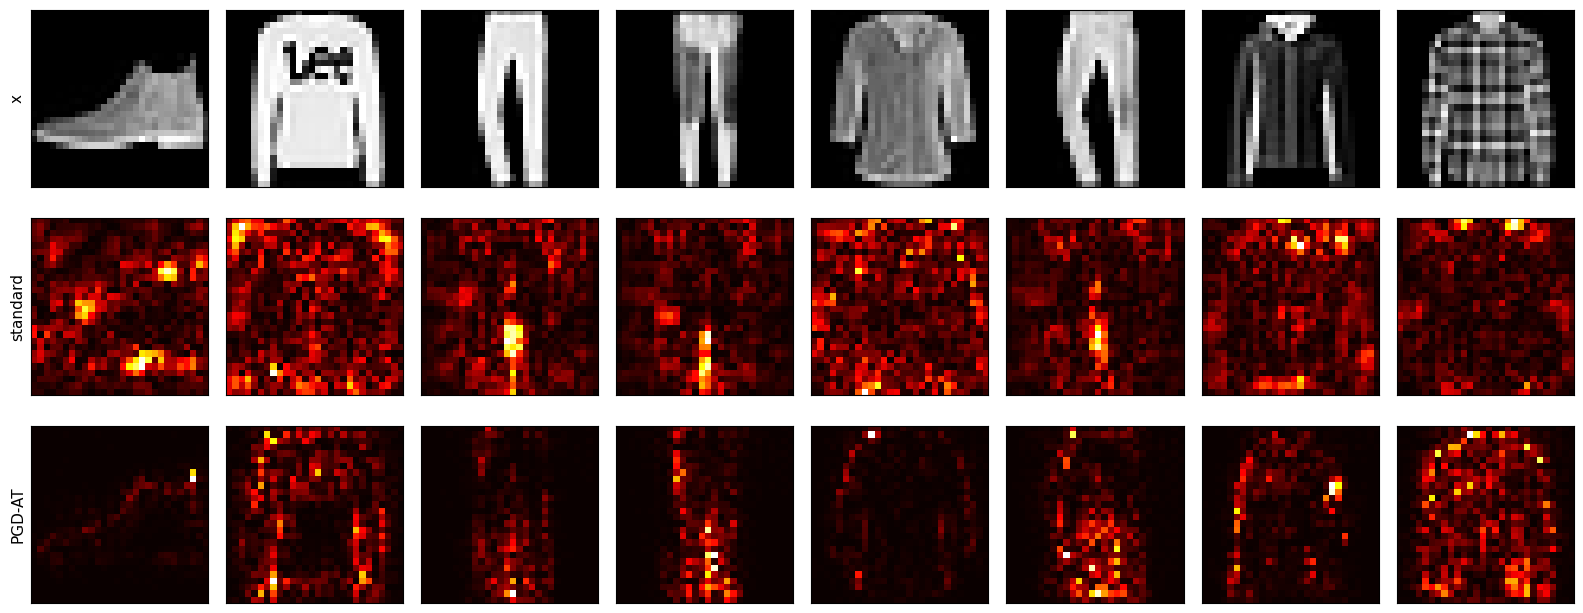

In [86]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
plt.gcf().savefig(Path('artifacts/plots') / 'fashion_input_gradients.png', dpi=140, bbox_inches='tight')
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** На изображениях показан модуль градиента логита истинного класса $|\nabla_x z_y|$. Доля массы на чёрном фоне определена как сумма $|g_i|$ на пикселях с $x_i=0$, делённая на общую сумму $|g_i|$ по каждому изображению с последующим усреднением. Числа приведены ниже; является ли доля PGD-AT ниже, определяется по данным.

Карты чувствительности служат лишь визуальной диагностикой. Они не сертифицируют устойчивость: градиент вычислен в одной точке, по логиту вместо cross-entropy, и может быть обманчив из-за gradient masking. Вывод о robustness делаем по сильным атакам из 6.1–6.2.


In [87]:
share_std, share_rob = shares['standard'], shares['PGD-AT']
share_bg = (x == 0).float().mean().item()
show_result('6.3 — градиенты по входу',
    f'- Доля фоновых пикселей: **{share_bg:.2%}**.\n'
    f'- Доля массы |grad| на фоне: standard **{share_std:.2%}**, PGD-AT **{share_rob:.2%}**; '
    f'разница PGD-AT − standard: **{100*(share_rob-share_std):+.2f} п.п.**.\n'
    f'- В этом прогоне на фоне PGD-AT сосредоточено **{"меньше" if share_rob < share_std else "не меньше"}** массы градиента, чем у standard. '
    'По одной салiency-карте устойчивость не определяется.')


### Фактический результат — 6.3 — градиенты по входу

- Доля фоновых пикселей: **49.83%**.
- Доля массы |grad| на фоне: standard **59.25%**, PGD-AT **22.62%**; разница PGD-AT − standard: **-36.63 п.п.**.
- В этом прогоне на фоне PGD-AT сосредоточено **меньше** массы градиента, чем у standard. По одной салiency-карте устойчивость не определяется.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [88]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'plots', 'resnet20.pt']


In [89]:

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
result_text = ('# Экспериментальные результаты домашней работы № 1\n\n'
               f'**Режим:** {"отладочный FAST_MODE=True (не финальная сдача)" if FAST_MODE else "финальный FAST_MODE=False"}  \n'
               f'**Устройство:** {device}  \n'
               f'**PyTorch:** {torch.__version__}  \n'
               f'**Ветка атаки:** {ATTACK_TRACK}  \n'
               f'**Бонусы:** {", ".join(sorted(BONUS_TASKS)) if BONUS_TASKS else "отключены"}\n\n'
               + '\n\n'.join(RESULTS_MD.values()) + '\n')
(artifact_dir / 'report.md').write_text(result_text, encoding='utf-8')
print('Создан artifacts/report.md; количество разделов с фактическими выводами:', len(RESULTS_MD))


Создан artifacts/report.md; количество разделов с фактическими выводами: 9


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [90]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        hv = torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True, allow_unused=True)
        return [torch.zeros_like(p) if h is None else h for h, p in zip(hv, params)]


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [91]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [92]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

eta=0.05  2/eta=  40.0  sharpness: start    4.4  max   42.4  mean 2nd half   31.8  final loss 0.1101
eta=0.1   2/eta=  20.0  sharpness: start    4.4  max   22.4  mean 2nd half   21.1  final loss 0.0859
eta=0.2   2/eta=  10.0  sharpness: start    4.4  max   12.3  mean 2nd half   11.1  final loss 0.0691


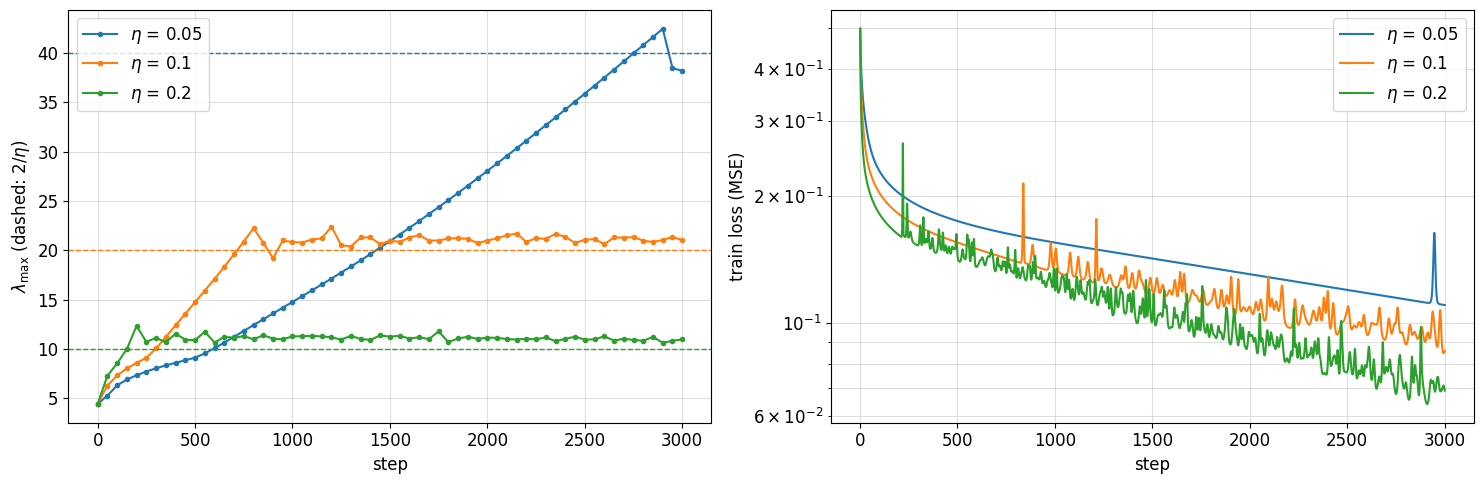

In [93]:
if '7.1' in BONUS_TASKS:
    EOS_LRS = [0.05, 0.1, 0.2]
    EIG_EVERY = 50
    eos = {}
    started = time.perf_counter()
    for lr_eos in EOS_LRS:
        model_eos = make_tanh_mlp(seed=0)
        params = list(model_eos.parameters())
        optimizer = torch.optim.SGD(params, lr=lr_eos, momentum=0.0)
        losses, eig_steps, sharpness = [], [], []
        v = None
        for step in range(EOS_STEPS + 1):
            if step % EIG_EVERY == 0:
                lam, v = top_eigenvalue(lambda: mse_loss(model_eos), params, iters=20, v=v)
                eig_steps.append(step)
                sharpness.append(lam)
            if step == EOS_STEPS:
                break
            loss = mse_loss(model_eos)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            if not math.isfinite(losses[-1]):
                print(f'eta={lr_eos}: loss diverged at step {step}')
                break
        eos[lr_eos] = dict(loss=losses, steps=eig_steps, sharpness=sharpness)
        tail = sharpness[len(sharpness) // 2:]
        print(f'eta={lr_eos:<5} 2/eta={2 / lr_eos:6.1f}  sharpness: start {sharpness[0]:6.1f}  '
              f'max {max(sharpness):6.1f}  mean 2nd half {np.mean(tail):6.1f}  final loss {losses[-1]:.4f}')
    RUN_TIMES['eos_seconds'] = time.perf_counter() - started

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    for color, (lr_eos, res) in zip(colors, eos.items()):
        ax1.plot(res['steps'], res['sharpness'], 'o-', color=color, markersize=3, label=rf'$\eta$ = {lr_eos}')
        ax1.axhline(2 / lr_eos, color=color, linestyle='--', linewidth=1)
        ax2.semilogy(range(1, len(res['loss']) + 1), res['loss'], color=color, label=rf'$\eta$ = {lr_eos}')
    ax1.set_xlabel('step')
    ax1.set_ylabel(r'$\lambda_{\max}$ (dashed: $2/\eta$)')
    ax2.set_xlabel('step')
    ax2.set_ylabel('train loss (MSE)')
    for ax in (ax1, ax2):
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
    plt.gcf().savefig(Path('artifacts/plots') / 'bonus_edge_of_stability.png', dpi=140, bbox_inches='tight')
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Для каждого learning rate вычисляется порог $2/\eta$, наибольшая измеренная sharpness, первый шаг пересечения порога, число шагов с ростом loss и конечный loss. Все эти сведения берутся из массивов `eos` в отчёте следующей ячейки; наличие *edge of stability* в конкретном запуске нельзя объявлять до измерения.

Условие $\eta < 2/\lambda_{max}$ является критерием устойчивости для фиксированной квадратичной модели с постоянным гессианом. У нелинейной нейросети гессиан меняется вместе с весами: локальный выход на границу может сопровождаться осцилляциями вдоль наиболее жёсткого направления и постепенным уменьшением общей ошибки. **Ограничения:** один seed, выбранная подвыборка, конечное число итераций Lanczos и замер sharpness раз в `EIG_EVERY` шагов; кратковременные пики между измерениями могут быть пропущены.


In [94]:
if '7.1' in BONUS_TASKS:
    lines = ['| eta | 2/eta | Sharpness max | Первый шаг ≥2/eta | Шагов роста loss | Финальный loss |',
             '|---:|---:|---:|---:|---:|---:|']
    for eta, v in eos.items():
        threshold = 2/eta
        first = next((step for step, sharp in zip(v['steps'], v['sharpness']) if sharp >= threshold), None)
        increases = sum(v['loss'][j] > v['loss'][j-1] for j in range(1, len(v['loss'])))
        lines.append(f'| {eta:g} | {threshold:.1f} | {max(v["sharpness"]):.2f} | {first if first is not None else "не достигнут"} | {increases}/{max(len(v["loss"])-1,0)} | {v["loss"][-1]:.4f} |')
    show_result('7.1 — edge of stability', '\n'.join(lines) +
        '\n\nПереход через порог определён только по точкам измерения sharpness; этот эксперимент не доказывает строгой глобальной сходимости.')


### Фактический результат — 7.1 — edge of stability

| eta | 2/eta | Sharpness max | Первый шаг ≥2/eta | Шагов роста loss | Финальный loss |
|---:|---:|---:|---:|---:|---:|
| 0.05 | 40.0 | 42.43 | 2800 | 28/2999 | 0.1101 |
| 0.1 | 20.0 | 22.39 | 750 | 1035/2999 | 0.0859 |
| 0.2 | 10.0 | 12.34 | 150 | 1351/2999 | 0.0691 |

Переход через порог определён только по точкам измерения sharpness; этот эксперимент не доказывает строгой глобальной сходимости.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [95]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        sh, sw = pair(stride)
        ph, pw = pair(padding)
        x = F.pad(x, (pw, pw, ph, ph))
        B, C_in, H, W = x.shape
        C_out, C_g, kh, kw = weight.shape
        g = groups
        Hf, Wf = H + kh - 1, W + kw - 1
        Xf = torch.fft.rfft2(x, s=(Hf, Wf))
        Kf = torch.fft.rfft2(weight.flip(-2, -1), s=(Hf, Wf))
        Xf = Xf.reshape(B, g, C_in // g, Hf, -1)
        Kf = Kf.reshape(g, C_out // g, C_g, Hf, -1)
        Yf = torch.einsum('bgchw,gochw->bgohw', Xf, Kf).reshape(B, C_out, Hf, -1)
        y = torch.fft.irfft2(Yf, s=(Hf, Wf))
        y = y[..., kh - 1:H, kw - 1:W][..., ::sh, ::sw]
        if bias is not None:
            y = y + bias.reshape(1, -1, 1, 1)
        return y.contiguous()

In [96]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?


**Ответ.**

### 1. Какая часть вычислений отбрасывается?

FFT-свёртка сначала вычисляет полную свёртку размером

$$
(H+k-1)\times(W+k-1).
$$

После выделения области `valid` остаётся

$$
(H-k+1)\times(W-k+1)
$$

значений (при отсутствии padding).

При использовании `stride = s` из допустимых выходных значений сохраняется только каждый $s$-й элемент по обеим пространственным осям.

Для достаточно больших карт доля сохраняемых значений приблизительно равна

$$
\frac{1}{s^2},
$$

а доля отбрасываемых составляет

$$
1-\frac{1}{s^2}.
$$

| Stride | Сохраняется | Отбрасывается |
|:---:|:---:|:---:|
| $s=1$ | 100% | 0% |
| $s=2$ | 25% | **75%** |
| $s=3$ | 11,1% | **88,9%** |

Это доли относительно области `valid`. Дополнительно при выделении этой области отбрасываются граничные значения полной свёртки.

### 2. Когда FFT-свёртка выгоднее?

FFT-свёртка может быть эффективнее прямой свёртки при следующих условиях:

- **Большие ядра.** Вычислительная сложность прямой свёртки растёт пропорционально $k^2$, тогда как FFT использует преобразования с затратами порядка $O(N\log N)$, где $N$ - размер дополненной карты.
- **Небольшой stride.** При `stride = 1` не возникает дополнительных потерь вычислений из-за прореживания выходной карты.
- **Много выходных каналов.** Преобразование Фурье входных данных можно повторно использовать для вычисления нескольких выходных каналов.

При небольших ядрах, например $3\times3$, и `stride = 2` прямая свёртка обычно выгоднее: она сразу вычисляет только необходимые значения, а FFT требует дополнительных преобразований и обработки промежуточных данных.

### Вывод

FFT-свёртка наиболее полезна при больших ядрах и небольшом stride, когда выигрыш от вычислений в частотной области перекрывает накладные расходы.

При увеличении stride её эффективность снижается, поскольку значительная часть вычисленных значений не используется. Для небольших ядер предпочтительнее оптимизированная прямая свёртка.


## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [97]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs
        X = M.float() if M.dtype in (torch.float16, torch.bfloat16) else M
        transposed = X.size(-2) > X.size(-1)
        if transposed:
            X = X.mT
        X = X / X.norm(dim=(-2, -1), keepdim=True).clamp_min(1e-7)
        for _ in range(steps):
            A = X @ X.mT
            X = a * X + (b * A + c * A @ A) @ X
        if transposed:
            X = X.mT
        return X.to(M.dtype)


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    if p.ndim < 2:
                        raise ValueError('ConvMuon supports only parameters with ndim >= 2')
                    state = self.state[p]
                    if 'momentum_buffer' not in state:
                        state['momentum_buffer'] = torch.zeros_like(p)
                    buf = state['momentum_buffer']
                    buf.lerp_(p.grad, 1 - mu)
                    update = p.grad.lerp(buf, mu)
                    U = update.reshape(p.shape[0], -1)
                    m, n = U.shape
                    p.add_(newton_schulz(U).reshape(p.shape), alpha=-group['lr'] * math.sqrt(max(1.0, m / n)))

In [98]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [99]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    set_seed(0)
    model_muon = ResNetCIFAR(20).to(device)
    conv_weights = [p for p in model_muon.parameters() if p.ndim == 4]
    other_decay = [p for p in model_muon.parameters() if p.ndim in (2, 3)]
    other_no_decay = [p for p in model_muon.parameters() if p.ndim <= 1]
    opt_muon = ConvMuon(conv_weights, lr=MUON_LR)
    opt_adamw = MyAdamW([g for g in [dict(params=other_decay, weight_decay=0.05),
                                     dict(params=other_no_decay, weight_decay=0.0)] if g['params']], lr=LR)
    total_steps = EPOCHS * math.ceil(len(X_train) / 256)
    schedulers = [torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, total_steps, 0.0))
                  for opt in (opt_muon, opt_adamw)]
    hist_muon = dict(train_loss=[], test_acc=[])
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        model_muon.train()
        loss_sum, n_seen = torch.zeros((), device=device), 0
        for x, y in iterate_batches(X_train, Y_train, 256, shuffle=True, transform=normalize):
            loss = F.cross_entropy(model_muon(x), y)
            opt_muon.zero_grad(set_to_none=True)
            opt_adamw.zero_grad(set_to_none=True)
            loss.backward()
            opt_muon.step()
            opt_adamw.step()
            for sched in schedulers:
                sched.step()
            loss_sum += loss.detach() * len(y)
            n_seen += len(y)
        hist_muon['train_loss'].append((loss_sum / n_seen).item())
        hist_muon['test_acc'].append(accuracy(predict_logits(model_muon, X_test, transform=normalize), Y_test))
        print(f'epoch {epoch + 1:>3}/{EPOCHS}  train loss {hist_muon["train_loss"][-1]:.4f}  '
              f'test acc {hist_muon["test_acc"][-1]:.4f}  {time.perf_counter() - started:.0f} s')
    model_muon.eval()
    RUN_TIMES['cifar_resnet20_muon_seconds'] = time.perf_counter() - started
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

epoch   1/20  train loss 1.1543  test acc 0.6460  10 s
epoch   2/20  train loss 0.6715  test acc 0.7511  20 s
epoch   3/20  train loss 0.5089  test acc 0.7774  31 s
epoch   4/20  train loss 0.4018  test acc 0.8167  41 s
epoch   5/20  train loss 0.3176  test acc 0.8093  52 s
epoch   6/20  train loss 0.2494  test acc 0.8127  62 s
epoch   7/20  train loss 0.1829  test acc 0.8344  73 s
epoch   8/20  train loss 0.1292  test acc 0.8278  83 s
epoch   9/20  train loss 0.0938  test acc 0.8315  94 s
epoch  10/20  train loss 0.0615  test acc 0.8387  105 s
epoch  11/20  train loss 0.0423  test acc 0.8304  116 s
epoch  12/20  train loss 0.0274  test acc 0.8393  127 s
epoch  13/20  train loss 0.0186  test acc 0.8431  138 s
epoch  14/20  train loss 0.0107  test acc 0.8430  149 s
epoch  15/20  train loss 0.0062  test acc 0.8451  160 s
epoch  16/20  train loss 0.0034  test acc 0.8480  171 s
epoch  17/20  train loss 0.0017  test acc 0.8478  182 s
epoch  18/20  train loss 0.0011  test acc 0.8476  193 s
e

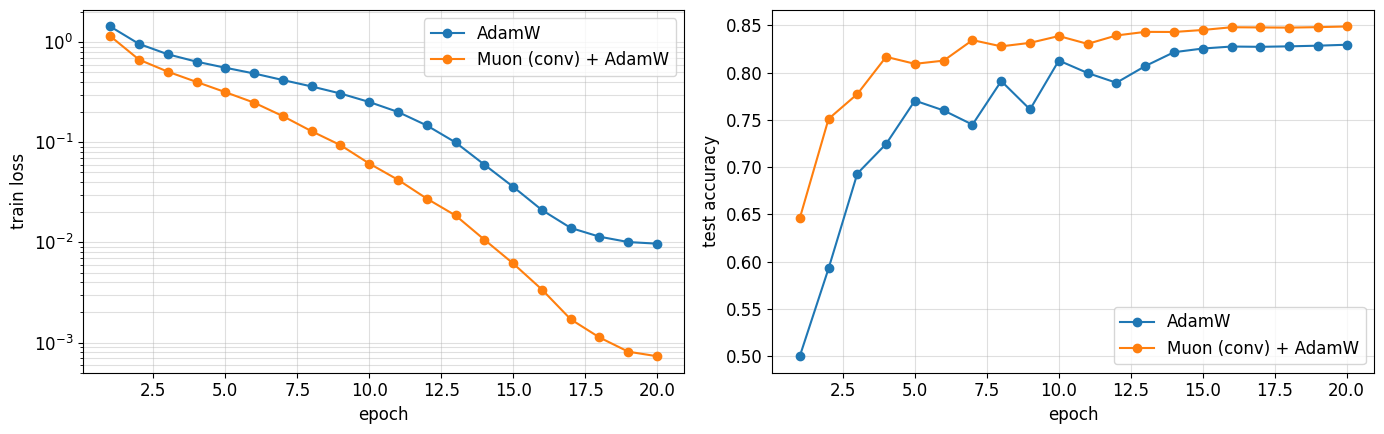

In [100]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
    plt.gcf().savefig(Path('artifacts/plots') / 'bonus_muon_comparison.png', dpi=140, bbox_inches='tight')
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Сравнение AdamW и Muon проводится на ResNet-20 с одинаковым числом эпох и seed. Автоматический отчёт ниже сравнивает train loss после первой и последней эпох, test accuracy и время; выигрыш оптимизатора не предполагается заранее. Рецепты используют разные learning rate и правила decay для свёрточных весов, поэтому такой эксперимент не изолирует один-единственный фактор.

На свёрточный параметр AdamW хранит два состояния ($m$ и $v$), Muon - один momentum buffer; для ConvMuon ортогонализация Ньютона–Шульца также требует временных матриц. Параметры BN и классификационной головы в данном эксперименте обновляет MyAdamW. Меньшая память постоянного состояния не гарантирует меньшего времени на шаг: Muon выполняет дополнительные матричные умножения.


In [101]:
if '7.3' in BONUS_TASKS:
    a, m = hist_adamw, hist_muon
    best_loss = 'Muon' if m['train_loss'][-1] < a['train_loss'][-1] else 'AdamW'
    best_acc = 'Muon' if m['test_acc'][-1] > a['test_acc'][-1] else 'AdamW'
    sec_a=RUN_TIMES['cifar_resnet20_seconds']; sec_m=RUN_TIMES['cifar_resnet20_muon_seconds']
    show_result('7.3 — Muon vs AdamW',
        '| Оптимизатор | Train loss, эпоха 1 | Train loss, последняя | Test accuracy, последняя | Время, мин |\n'
        '|---|---:|---:|---:|---:|\n'
        f'| AdamW | {a["train_loss"][0]:.4f} | {a["train_loss"][-1]:.4f} | {a["test_acc"][-1]:.2%} | {sec_a/60:.2f} |\n'
        f'| Muon+AdamW | {m["train_loss"][0]:.4f} | {m["train_loss"][-1]:.4f} | {m["test_acc"][-1]:.2%} | {sec_m/60:.2f} |\n\n'
        f'Финальный train loss ниже у **{best_loss}**, test accuracy выше у **{best_acc}** '
        f'(Muon−AdamW: **{100*(m["test_acc"][-1]-a["test_acc"][-1]):+.2f} п.п.**). '
        'Один seed и разные гиперпараметры не позволяют уверенно ранжировать алгоритмы в целом.')


### Фактический результат — 7.3 — Muon vs AdamW

| Оптимизатор | Train loss, эпоха 1 | Train loss, последняя | Test accuracy, последняя | Время, мин |
|---|---:|---:|---:|---:|
| AdamW | 1.4392 | 0.0097 | 82.95% | 3.43 |
| Muon+AdamW | 1.1543 | 0.0007 | 84.88% | 3.60 |

Финальный train loss ниже у **Muon**, test accuracy выше у **Muon** (Muon−AdamW: **+1.93 п.п.**). Один seed и разные гиперпараметры не позволяют уверенно ранжировать алгоритмы в целом.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [102]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [103]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.922, 'L0, k=5': 0.636}
standard    0.922  0.890  0.856  0.776  0.636  0.398  0.136  0.024
PGD-AT      0.858  0.822  0.790  0.766  0.728  0.636  0.406  0.292


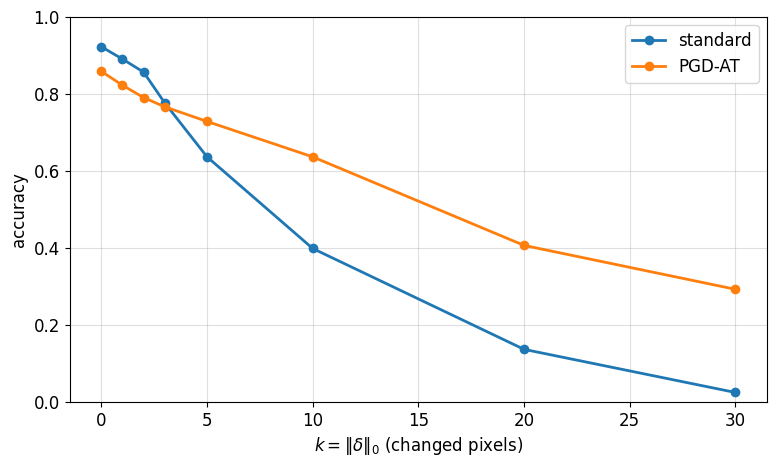

In [104]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
    plt.gcf().savefig(Path('artifacts/plots') / 'bonus_l0_curves.png', dpi=140, bbox_inches='tight')
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Сравниваем accuracy после жадной атаки с изменением до $k$ отдельных пикселей у стандартной и PGD-AT моделей. Доли для $k=5$ и $k=30$ и знак выигрыша вычисляются автоматически ниже. В отличие от PGD, такая атака лишь приближённо оптимизирует $L_0$-ограничение, поэтому это эмпирическая, а не гарантированная оценка устойчивости.

$L_\infty$-обучение при $\varepsilon=0.1$ допускает изменение каждого пикселя максимум на 0.1. Одна замена 0 на 1 имеет $\|\delta\|_0=1$, но $\|\delta\|_\infty=1$, что выходит за защищаемый шар. Поэтому перенос устойчивости из $L_\infty$ на $L_0$ необязателен.


In [105]:
if '7.4' in BONUS_TASKS:
    lines = ['| k изменённых пикселей | Standard | PGD-AT | Δ PGD-AT−Standard, п.п. |', '|---:|---:|---:|---:|']
    for k, a, b in zip(ks, l0_curves['standard'], l0_curves['PGD-AT']):
        lines.append(f'| {k} | {a:.2%} | {b:.2%} | {100*(b-a):+.2f} |')
    index = ks.index(5)
    benefit = l0_curves['PGD-AT'][index] - l0_curves['standard'][index]
    show_result('7.4 — L0 атака', '\n'.join(lines) + '\n\n' +
         f'При k=5 PGD-AT **{"устойчивее по этой атаке" if benefit>0 else "не устойчивее по этой атаке"}** '
         f'(разница **{100*benefit:+.2f} п.п.**). Это не сертификат защиты от L0-возмущений.')


### Фактический результат — 7.4 — L0 атака

| k изменённых пикселей | Standard | PGD-AT | Δ PGD-AT−Standard, п.п. |
|---:|---:|---:|---:|
| 0 | 92.20% | 85.80% | -6.40 |
| 1 | 89.00% | 82.20% | -6.80 |
| 2 | 85.60% | 79.00% | -6.60 |
| 3 | 77.60% | 76.60% | -1.00 |
| 5 | 63.60% | 72.80% | +9.20 |
| 10 | 39.80% | 63.60% | +23.80 |
| 20 | 13.60% | 40.60% | +27.00 |
| 30 | 2.40% | 29.20% | +26.80 |

При k=5 PGD-AT **устойчивее по этой атаке** (разница **+9.20 п.п.**). Это не сертификат защиты от L0-возмущений.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [106]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5  clean 0.729  FGSM 0.665  PGD-20 0.040  3 s
epoch 2/5  clean 0.564  FGSM 0.913  PGD-20 0.001  6 s
epoch 3/5  clean 0.469  FGSM 0.972  PGD-20 0.001  8 s
epoch 4/5  clean 0.405  FGSM 0.977  PGD-20 0.000  11 s
epoch 5/5  clean 0.342  FGSM 0.989  PGD-20 0.000  14 s
FGSM-RS
epoch 1/5  clean 0.766  FGSM 0.625  PGD-20 0.370  3 s
epoch 2/5  clean 0.789  FGSM 0.650  PGD-20 0.385  6 s
epoch 3/5  clean 0.797  FGSM 0.711  PGD-20 0.420  8 s
epoch 4/5  clean 0.797  FGSM 0.701  PGD-20 0.427  11 s
epoch 5/5  clean 0.805  FGSM 0.748  PGD-20 0.346  14 s


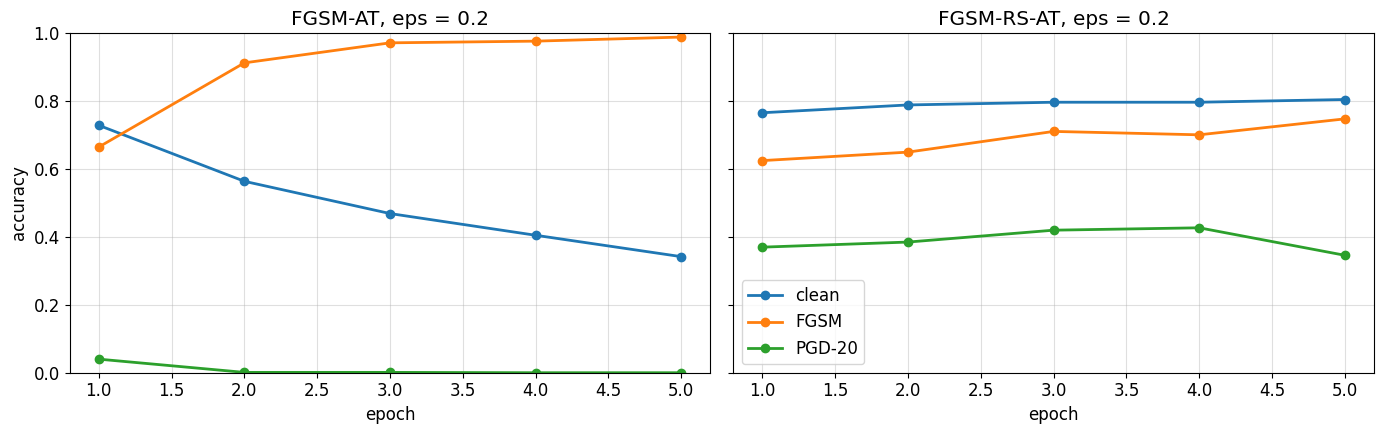

In [107]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    Path('artifacts/plots').mkdir(parents=True, exist_ok=True)
    plt.gcf().savefig(Path('artifacts/plots') / 'bonus_catastrophic_overfitting.png', dpi=140, bbox_inches='tight')
    plt.show()

In [108]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.30859375, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.72265625, 'pgd20': 0.34765625, 'pgd100_x5': 0.28125, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** Catastrophic overfitting диагностируется по сильному падению PGD accuracy на фоне заметно более высокой FGSM accuracy; сам по себе зазор ещё не доказывает, что произошло резкое падение в ходе обучения. В отчёте ниже автоматически найдены эпоха наибольшего падения PGD-20, разрывы FGSM−PGD на последней эпохе и результаты усиленной атаки для обеих моделей.

Random start меняет исходную точку линейного приближения внутри шара и может ослаблять gradient masking, но не даёт гарантии. Если резкий спад за фиксированные 5 эпох не наблюдается, корректно так и написать, а как проверяемую гипотезу предложить другой радиус или длительность обучения в отдельном контрольном эксперименте, не изменяя основной протокол.


In [109]:
if '7.5' in BONUS_TASKS:
    lines = ['| Метод | Наибольшее падение PGD за эпоху | Эпоха (конец интервала) | FGSM, конец | PGD-20, конец | PGD-100×5, конец |',
             '|---|---:|---:|---:|---:|---:|']
    for key in ('FGSM', 'FGSM-RS'):
        hist = co_history[key]
        drops = [(hist['pgd'][i-1]-hist['pgd'][i],i+1) for i in range(1,len(hist['pgd']))]
        drop,epoch = max(drops, default=(0, None))
        val=co_checks[key]
        lines.append(f'| {key} | {100*drop:+.2f} п.п. | {epoch if epoch is not None else "—"} | {hist["fgsm"][-1]:.2%} | {hist["pgd"][-1]:.2%} | {val["pgd100_x5"]:.2%} |')
    desc = 'Резкое падение >=20 п.п. за эпоху зафиксировано хотя бы в одном прогоне.' if any(
        max((v['pgd'][i-1]-v['pgd'][i] for i in range(1,len(v['pgd']))), default=0)>=0.2 for v in co_history.values()) else (
        'Падения >=20 п.п. за одну эпоху не зафиксировано: catastrophic overfitting по данному эвристическому порогу не доказан.')
    show_result('7.5 — catastrophic overfitting', '\n'.join(lines) + '\n\n' + desc +
        ' Для проверки гипотезы о зависимости от eps и длительности нужен отдельный контроль с теми же настройками основной серии.')


### Фактический результат — 7.5 — catastrophic overfitting

| Метод | Наибольшее падение PGD за эпоху | Эпоха (конец интервала) | FGSM, конец | PGD-20, конец | PGD-100×5, конец |
|---|---:|---:|---:|---:|---:|
| FGSM | +3.90 п.п. | 2 | 98.90% | 0.00% | 0.00% |
| FGSM-RS | +8.10 п.п. | 5 | 74.80% | 34.60% | 28.12% |

Падения >=20 п.п. за одну эпоху не зафиксировано: catastrophic overfitting по данному эвристическому порогу не доказан. Для проверки гипотезы о зависимости от eps и длительности нужен отдельный контроль с теми же настройками основной серии.

In [110]:
bonus_metrics = dict(fast_mode=FAST_MODE, bonus_tasks=sorted(BONUS_TASKS), timings=RUN_TIMES)
if '7.1' in BONUS_TASKS:
    bonus_metrics['7.1'] = dict(lrs=EOS_LRS, eig_every=EIG_EVERY, runs={str(k): v for k, v in eos.items()})
if '7.3' in BONUS_TASKS:
    bonus_metrics['7.3'] = dict(muon_lr=MUON_LR, adamw=hist_adamw, muon=hist_muon)
if '7.4' in BONUS_TASKS:
    bonus_metrics['7.4'] = dict(ks=ks, accuracy=l0_curves)
if '7.5' in BONUS_TASKS:
    bonus_metrics['7.5'] = dict(eps=EPS_CO, history=co_history, sanity=co_checks)
(artifact_dir / 'bonus_metrics.json').write_text(json.dumps(json_ready(bonus_metrics), ensure_ascii=False, indent=2,
                                                          allow_nan=False), encoding='utf-8')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['bonus_metrics.json', 'fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'plots', 'report.md', 'resnet20.pt']


In [111]:

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
result_text = ('# Экспериментальные результаты домашней работы № 1\n\n'
               f'**Режим:** {"отладочный FAST_MODE=True (не финальная сдача)" if FAST_MODE else "финальный FAST_MODE=False"}  \n'
               f'**Устройство:** {device}  \n'
               f'**PyTorch:** {torch.__version__}  \n'
               f'**Ветка атаки:** {ATTACK_TRACK}  \n'
               f'**Бонусы:** {", ".join(sorted(BONUS_TASKS)) if BONUS_TASKS else "отключены"}\n\n'
               + '\n\n'.join(RESULTS_MD.values()) + '\n')
(artifact_dir / 'report.md').write_text(result_text, encoding='utf-8')
print('Создан artifacts/report.md; количество разделов с фактическими выводами:', len(RESULTS_MD))


Создан artifacts/report.md; количество разделов с фактическими выводами: 13


In [112]:
import shutil
from pathlib import Path
from google.colab import files

artifacts = Path("artifacts")

assert artifacts.exists(), "Папка artifacts не найдена!"

print("Содержимое artifacts:")
for path in artifacts.rglob("*"):
    if path.is_file():
        print(path, f"({path.stat().st_size / 1024:.1f} KB)")

shutil.make_archive(
    "artifacts", "zip",
    root_dir=".",
    base_dir="artifacts"
)

files.download("artifacts.zip")

Содержимое artifacts:
artifacts/fashion_standard.pt (199.0 KB)
artifacts/metrics.json (7.5 KB)
artifacts/fashion_pgd_at.pt (199.0 KB)
artifacts/bonus_metrics.json (283.3 KB)
artifacts/report.md (8.3 KB)
artifacts/resnet20.pt (1108.1 KB)
artifacts/plots/fashion_perturbations.png (78.1 KB)
artifacts/plots/fashion_input_gradients.png (64.2 KB)
artifacts/plots/cifar_resnet20.png (70.8 KB)
artifacts/plots/bonus_catastrophic_overfitting.png (69.9 KB)
artifacts/plots/bonus_edge_of_stability.png (165.4 KB)
artifacts/plots/bonus_l0_curves.png (59.4 KB)
artifacts/plots/cifar_plain_ablation.png (86.5 KB)
artifacts/plots/bonus_muon_comparison.png (112.0 KB)
artifacts/plots/fashion_pgd_l2_curve.png (38.6 KB)
artifacts/plots/fashion_pgd_at_robustness.png (56.9 KB)
artifacts/plots/fashion_targeted_matrix.png (120.1 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>